# Litmus - Persuasion Technique Detector
## Part A: Multi-label technique classification

**Task:** A text extractor (provided) gives us the raw text of an uploaded meme. From that text I predict which of 20 persuasion techniques it uses. A meme can use none, one or several at once.

**Constraints from the brief:**
- Nothing a student enters may leave the device, so no hosted model APIs at inference time. Pretrained weights can be downloaded once and run locally.
- It has to run on a single T4 GPU (16GB) and answer while a class waits.
- I can fine-tune a pretrained text encoder, but not one that was already trained on persuasion or propaganda data.
- Neural network techniques only.
- A clearly self-built, self-trained part is required, separate from the pretrained part.

**Data:** It has 688 train, 63 dev and 200 test memes, each with zero or more of 20 techniques. I used the competition's own split instead of re-splitting, because it is already a clean partition and keeps my numbers comparable to the dataset's description.

**Approach:** I followed the fine-tuning workflow from the labs: `AutoModelForSequenceClassification` with a new head, linear probing, then full fine-tuning, plus a LoRA run to argue about compute. The main change is the multi-label handling (a sigmoid per technique and a tuned threshold instead of one softmax), and I point out each place where that changes something from the labs.

## Setup

In [54]:

import os, json, random, time, warnings
from pathlib import Path
from collections import Counter
from peft import LoraConfig, get_peft_model, TaskType

os.environ['HF_HUB_DISABLE_TELEMETRY'] = '1'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
warnings.filterwarnings('ignore', message='.*HF_TOKEN.*')
warnings.filterwarnings('ignore', message='.*unauthenticated.*')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import f1_score, precision_recall_fscore_support

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')


Using device: cpu


## 1. Loading the Data

In [55]:

DATA_DIR = Path("C:/Users/user/Downloads/data_2026_A2/data")

def load_task1(split):
    with open(DATA_DIR / f"{split}_set_task1.txt", encoding="utf-8") as f:
        return json.load(f)

train_raw = load_task1("training")
dev_raw = load_task1("dev")
test_raw = load_task1("test")

print(f"Train: {len(train_raw)} | Dev: {len(dev_raw)} | Test: {len(test_raw)}")
print("\nExample:")
print(json.dumps(train_raw[2], indent=2)[:400])


Train: 688 | Dev: 63 | Test: 200

Example:
{
  "id": "96",
  "labels": [
    "Loaded Language",
    "Name calling/Labeling",
    "Slogans",
    "Smears"
  ],
  "text": "SO BERNIE BROS HAVEN'T COMMITTED VIOLENCE EH?\n\nPOWER COMES FROM THE BARREL OF A GUN, COMRADES.\n\nWHAT ABOUT THE ONE WHO SHOT CONGRESSMAN SCALISE OR THE DAYTON OHIO MASS SHOOTER?\n"
}


In [56]:

all_labels = sorted({label for d in train_raw + dev_raw + test_raw for label in d["labels"]})
NUM_LABELS = len(all_labels)
LABEL_TO_IDX = {l: i for i, l in enumerate(all_labels)}
IDX_TO_LABEL = {i: l for l, i in LABEL_TO_IDX.items()}
print(f"{NUM_LABELS} distinct techniques appear in the corpus:")
for l in all_labels:
    print(" -", l)


20 distinct techniques appear in the corpus:
 - Appeal to authority
 - Appeal to fear/prejudice
 - Bandwagon
 - Black-and-white Fallacy/Dictatorship
 - Causal Oversimplification
 - Doubt
 - Exaggeration/Minimisation
 - Flag-waving
 - Glittering generalities (Virtue)
 - Loaded Language
 - Misrepresentation of Someone's Position (Straw Man)
 - Name calling/Labeling
 - Obfuscation, Intentional vagueness, Confusion
 - Presenting Irrelevant Data (Red Herring)
 - Reductio ad hitlerum
 - Repetition
 - Slogans
 - Smears
 - Thought-terminating cliché
 - Whataboutism


### A gap in the data: 22 techniques in the taxonomy, only 20 in the corpus

The task says the taxonomy has 22 persuasion techniques, but the corpus covers 20. The file techniques_list_task3.txt lists the full taxonomy, so I can check exactly which ones are missing.

In [57]:

with open("techniques_list_task3.txt", encoding="utf-8") as f:
    full_taxonomy = [line.strip() for line in f if line.strip()]

print(f"Full published taxonomy: {len(full_taxonomy)} techniques")
print(f"Techniques actually appearing in train/dev/test: {len(all_labels)}")

never_seen = [t for t in full_taxonomy if t not in LABEL_TO_IDX]
unexpected = [l for l in all_labels if l not in full_taxonomy]

print(f"\nIn the taxonomy but with zero training examples: {never_seen}")
if unexpected:
    print(f"In the corpus but missing from the taxonomy file (unexpected): {unexpected}")
else:
    print("Every corpus label matches the taxonomy file exactly (no naming mismatches).")


Full published taxonomy: 22 techniques
Techniques actually appearing in train/dev/test: 20

In the taxonomy but with zero training examples: ['Transfer', 'Appeal to (Strong) Emotions']
Every corpus label matches the taxonomy file exactly (no naming mismatches).


The model can never predict `Transfer` or `Appeal to (Strong) Emotions`. That is not because it is bad at them. It has never seen a single labelled example of either. If a Year 10 student uploads a meme that uses only one of these techniques, the correct output of this tool is "no technique detected", and on screen that looks exactly the same as the model being wrong. This is a limit of the training data and not of the architecture. It matters for Part C because it is a gap between what the lesson's taxonomy promises and what the tool can actually recognise, and it is separate from the domain gap in C4.

## 2. Exploratory Data Analysis

Memes with no technique label: 143 / 688 (20.8%)
Of the rest, average techniques per meme: 2.17 (max 8)


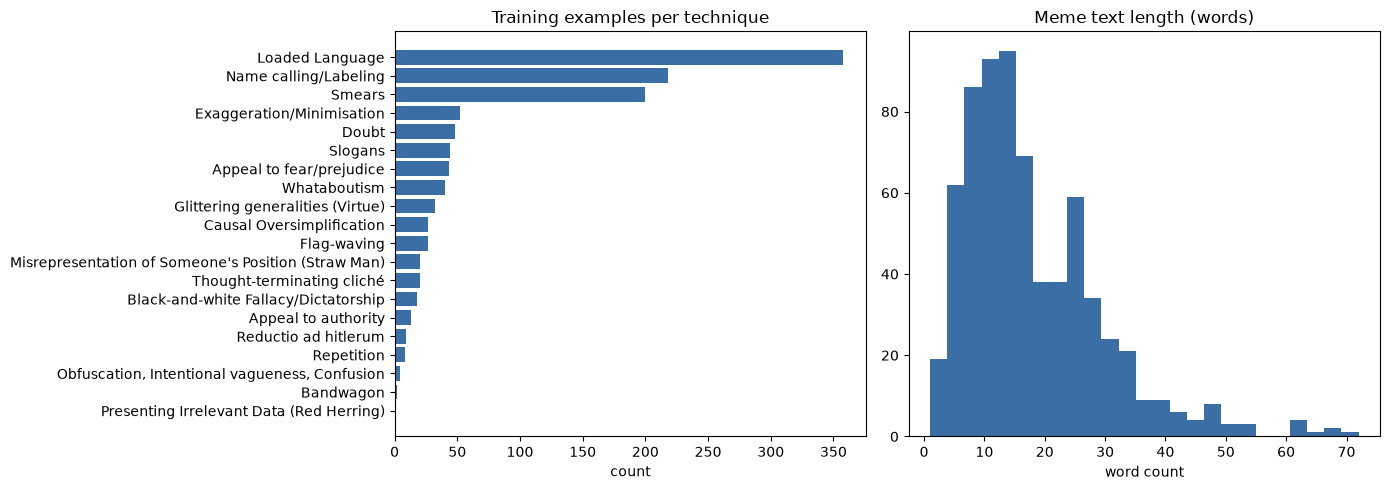

In [58]:

label_counts = Counter(label for d in train_raw for label in d["labels"])
n_empty = sum(1 for d in train_raw if len(d["labels"]) == 0)
n_labels_per_meme = [len(d["labels"]) for d in train_raw if len(d["labels"]) > 0]

print(f"Memes with no technique label: {n_empty} / {len(train_raw)} ({n_empty/len(train_raw)*100:.1f}%)")
print(f"Of the rest, average techniques per meme: {np.mean(n_labels_per_meme):.2f} (max {max(n_labels_per_meme)})")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
counts_sorted = sorted(label_counts.items(), key=lambda x: -x[1])
axes[0].barh([c[0] for c in counts_sorted][::-1], [c[1] for c in counts_sorted][::-1], color="#3b6ea5")
axes[0].set_title("Training examples per technique"); axes[0].set_xlabel("count")

word_counts = [len(d["text"].split()) for d in train_raw]
axes[1].hist(word_counts, bins=25, color="#3b6ea5")
axes[1].set_title("Meme text length (words)"); axes[1].set_xlabel("word count")
plt.tight_layout(); plt.show()


**What the EDA shows:**
1. About 21% of training memes (143 of 688) have no technique at all, so the model has to be as good at saying "nothing here" as at naming a technique.
2. The classes are very imbalanced. `Loaded Language` appears in roughly 360 training memes, while the eight rarest techniques add up to only about 75 between them. I handle this with per-class weights in the loss.
3. The texts are short, which suits a small pretrained encoder and the T4 'answer while a class waits' constraint.

## 3. Tokenizing and Building the Dataset

I used the HFDataset pattern, tokenize everything and return a dict of tensors per item. The one change is that `labels` is a float multi-hot vector of length 20 (one flag per technique) instead of a single class index, since a meme can use several techniques or none.

In [59]:

MODEL_NAME = "distilbert-base-uncased"
MAX_LENGTH = 128

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class HFMultiLabelDataset(Dataset):
    def __init__(self, records, tokenizer, max_length=MAX_LENGTH):
        texts = [r["text"] for r in records]
        self.encodings = tokenizer(
            texts, padding="max_length", truncation=True,
            max_length=max_length, return_tensors="pt",
        )
        self.labels = torch.zeros(len(records), NUM_LABELS)
        for i, r in enumerate(records):
            for label in r["labels"]:
                self.labels[i, LABEL_TO_IDX[label]] = 1.0

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            "input_ids": self.encodings["input_ids"][idx],
            "attention_mask": self.encodings["attention_mask"][idx],
            "labels": self.labels[idx],
        }

train_ds = HFMultiLabelDataset(train_raw, tokenizer)
dev_ds = HFMultiLabelDataset(dev_raw, tokenizer)
test_ds = HFMultiLabelDataset(test_raw, tokenizer)

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True)
dev_loader = DataLoader(dev_ds, batch_size=32, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False)

print(f"Train: {len(train_ds)}, Dev: {len(dev_ds)}, Test: {len(test_ds)}")


Train: 688, Dev: 63, Test: 200


## 4. Model: Pretrained Encoder + New Classification Head

I used AutoModelForSequenceClassification instead of writing my own wrapper. Loading DistilBERT this way puts a new pre_classifier and classifier on top of the pretrained transformer. They start from random weights and are specific to the 20 techniques. This pair is my self-built, self-trained part for the task. It is like swapping the final layer of a pretrained image model where the backbone is reused and the decision layer is trained from scratch.

Setting `problem_type="multi_label_classification"` makes the model use an independent sigmoid for each technique with BCEWithLogitsLoss, instead of a softmax over classes. This is the one real design change that multi-label forces.

I chose DistilBERT for three reasons. It only had generic masked-language-model pretraining, with no persuasion or propaganda data, so it meets that rule. It is a smaller, faster version of the larger BERT model. And it has about 66M parameters, which is small for a T4.

In [60]:

def create_model():
    return AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=NUM_LABELS,
        problem_type="multi_label_classification",
        token=False, attn_implementation="eager",
    ).to(device)

model = create_model()
print(model.classifier)  #the self-built, self-trained head that is randomly initialised


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Linear(in_features=768, out_features=20, bias=True)


## 5. Training Utilities

The loss is computed outside the model using a criterion I pass in, which is what lets me plug in the class-weighted loss in the next section. Each of the 20 outputs is thresholded on its own, and micro-F1 replaces accuracy as the tracked metric.

In [61]:

def train_one_epoch_hf(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0.0
    for batch in loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        y = batch['labels'].to(device)
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        logits = outputs.logits
        loss = criterion(logits, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * y.size(0)
    return total_loss / len(loader.dataset)


@torch.inference_mode()
def predict_probs(model, loader):
    model.eval()
    all_probs, all_labels = [], []
    for batch in loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        all_probs.append(torch.sigmoid(outputs.logits).cpu())
        all_labels.append(batch['labels'])
    return torch.cat(all_probs).numpy(), torch.cat(all_labels).numpy()


def evaluate_hf(model, loader, criterion, threshold=0.5):
    model.eval()
    total_loss, n = 0.0, 0
    with torch.inference_mode():
        for batch in loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            y = batch['labels'].to(device)
            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            loss = criterion(outputs.logits, y)
            total_loss += loss.item() * y.size(0)
            n += y.size(0)
    probs, true = predict_probs(model, loader)
    preds = (probs >= threshold).astype(int)
    micro_f1 = f1_score(true, preds, average='micro', zero_division=0)
    macro_f1 = f1_score(true, preds, average='macro', zero_division=0)
    return total_loss / n, micro_f1, macro_f1


def run_experiment_hf(model, optimizer, criterion, train_loader, val_loader,
                       epochs=5, name='Model'):
    history = {'train_loss': [], 'val_loss': [], 'val_micro_f1': [], 'val_macro_f1': []}
    for epoch in range(epochs):
        tl = train_one_epoch_hf(model, train_loader, optimizer, criterion)
        vl, micro_f1, macro_f1 = evaluate_hf(model, val_loader, criterion)
        history['train_loss'].append(tl)
        history['val_loss'].append(vl)
        history['val_micro_f1'].append(micro_f1)
        history['val_macro_f1'].append(macro_f1)
        if (epoch + 1) % max(1, epochs // 3) == 0 or epoch == 0:
            print(f'[{name}] Epoch {epoch+1}/{epochs} - Train loss: {tl:.4f} | Val loss: {vl:.4f} | Val micro-F1: {micro_f1:.4f} | Val macro-F1: {macro_f1:.4f}')
    return history


def plot_experiments(results, show_train=True, show_val=True):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for name, hist in results.items():
        epochs = range(1, len(hist['train_loss']) + 1)
        if show_train:
            axes[0].plot(epochs, hist['train_loss'], label=f'{name} (Train)', marker='o', markersize=3)
        if show_val:
            axes[0].plot(epochs, hist['val_loss'], label=f'{name} (Val)', linestyle='--', marker='x', markersize=3)
            axes[1].plot(epochs, hist['val_micro_f1'], label=f'{name} (micro-F1)', marker='o', markersize=3)
            axes[1].plot(epochs, hist['val_macro_f1'], label=f'{name} (macro-F1)', linestyle='--', marker='x', markersize=3)
    axes[0].set_title('Loss'); axes[0].set_xlabel('Epoch'); axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
    axes[1].set_title('Validation F1'); axes[1].set_xlabel('Epoch'); axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
    plt.tight_layout(); plt.show()


def count_parameters(model):
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    print(f'Trainable: {trainable:,} / {total:,} parameters ({trainable/total*100:.2f}%)')


## 6. Class-Weighted Loss

Each technique gets a pos_weight based on how rare it is, as the EDA suggested. Missing a positive for a rare technique costs more than missing one for `Loaded Language`. Without this, the loss is dominated by the few common techniques and the rare ones barely affect training.

In [62]:

pos_counts = np.array([label_counts.get(l, 0) for l in all_labels], dtype=np.float32)
neg_counts = len(train_raw) - pos_counts
pos_weight = torch.tensor(neg_counts / np.clip(pos_counts, 1, None), dtype=torch.float32).to(device)
print("Per-class pos_weight:")
print(pd.Series(pos_weight.cpu().numpy(), index=all_labels).round(1).sort_values(ascending=False))

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)


Per-class pos_weight:
Presenting Irrelevant Data (Red Herring)               687.000000
Bandwagon                                              343.000000
Obfuscation, Intentional vagueness, Confusion          171.000000
Repetition                                              85.000000
Reductio ad hitlerum                                    75.400002
Appeal to authority                                     51.900002
Black-and-white Fallacy/Dictatorship                    37.200001
Misrepresentation of Someone's Position (Straw Man)     33.400002
Thought-terminating cliché                              33.400002
Flag-waving                                             24.500000
Causal Oversimplification                               24.500000
Glittering generalities (Virtue)                        20.500000
Whataboutism                                            16.200001
Appeal to fear/prejudice                                15.000000
Slogans                                               

## 7. Fine-Tuning: Linear Probing, then Full Fine-Tuning

In step 1 I freeze the pretrained backbone and train only the new head. This is a fast, low-risk check that the head alone can learn something. In step 2 I unfreeze everything and keep training the same model with a much smaller learning rate, because big updates at this stage would damage the pretrained weights instead of adapting them.

In [63]:

all_results = {}
torch.manual_seed(SEED)
model = create_model()

# Step 1: Linear probing
for param in model.distilbert.parameters():
    param.requires_grad = False

print('Step 1: Linear Probing')
count_parameters(model)

optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-3)
all_results['DistilBERT (linear probe)'] = run_experiment_hf(
    model, optimizer, criterion, train_loader, dev_loader, epochs=5, name='probe')


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step 1: Linear Probing
Trainable: 605,972 / 66,968,852 parameters (0.90%)
[probe] Epoch 1/5 - Train loss: 1.4061 | Val loss: 2.1260 | Val micro-F1: 0.2267 | Val macro-F1: 0.1030
[probe] Epoch 2/5 - Train loss: 1.2533 | Val loss: 1.9744 | Val micro-F1: 0.3672 | Val macro-F1: 0.1823
[probe] Epoch 3/5 - Train loss: 1.2035 | Val loss: 1.7064 | Val micro-F1: 0.2948 | Val macro-F1: 0.1979
[probe] Epoch 4/5 - Train loss: 1.1836 | Val loss: 1.7212 | Val micro-F1: 0.2327 | Val macro-F1: 0.1813
[probe] Epoch 5/5 - Train loss: 1.0528 | Val loss: 1.8802 | Val micro-F1: 0.3080 | Val macro-F1: 0.1783


In [64]:

# Step 2: Fine-tuning - unfreeze the backbone and continue training the same model
for param in model.distilbert.parameters():
    param.requires_grad = True

print('Step 2: Fine-Tuning')
count_parameters(model)

optimizer = optim.AdamW(model.parameters(), lr=2e-5, weight_decay=0.01)
all_results['DistilBERT (fine-tuned)'] = run_experiment_hf(
    model, optimizer, criterion, train_loader, dev_loader, epochs=8, name='fine-tune')

plot_experiments(all_results)


Step 2: Fine-Tuning
Trainable: 66,968,852 / 66,968,852 parameters (100.00%)


In [ ]:
import copy, itertools

def run_experiment_best(model, optimizer, criterion, train_loader, val_loader, epochs, name):
    history = {'train_loss': [], 'val_loss': [], 'val_micro_f1': [], 'val_macro_f1': []}
    best = {'score': -1.0, 'epoch': 0, 'state': None}
    for epoch in range(epochs):
        tl = train_one_epoch_hf(model, train_loader, optimizer, criterion)
        vl, mi, ma = evaluate_hf(model, val_loader, criterion)
        history['train_loss'].append(tl); history['val_loss'].append(vl)
        history['val_micro_f1'].append(mi); history['val_macro_f1'].append(ma)
        if ma > best['score']:
            best.update(score=ma, epoch=epoch + 1,
                        state={k: v.detach().cpu().clone() for k, v in model.state_dict().items()})
    return history, best


def train_config(lr, weight_decay, batch_size, seed, probe_epochs=5, ft_epochs=8):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    m = create_model()
    loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))
    # Step 1: linear probe (same as the main pipeline)
    for p in m.distilbert.parameters():
        p.requires_grad = False
    opt = optim.Adam(filter(lambda p: p.requires_grad, m.parameters()), lr=1e-3)
    for _ in range(probe_epochs):
        train_one_epoch_hf(m, loader, opt, criterion)
    # Step 2: full fine-tuning
    for p in m.distilbert.parameters():
        p.requires_grad = True
    opt = optim.AdamW(m.parameters(), lr=lr, weight_decay=weight_decay)
    hist, best = run_experiment_best(m, opt, criterion, loader, dev_loader, ft_epochs,
                                     name=f'lr={lr}, bs={batch_size}')
    return m, hist, best


GRID = {'lr': [1e-5, 2e-5, 5e-5], 'batch_size': [16, 32]}
SEEDS = [42, 43]
WD = 0.01

rows = []
for lr, bs in itertools.product(GRID['lr'], GRID['batch_size']):
    for s in SEEDS:
        m, hist, best = train_config(lr, WD, bs, s)
        rows.append({'lr': lr, 'batch_size': bs, 'seed': s,
                     'best_epoch': best['epoch'], 'dev_macro_f1': best['score'],
                     'dev_micro_f1': hist['val_micro_f1'][best['epoch'] - 1]})
        del m, best
        torch.cuda.empty_cache()
        print(f"lr={lr:g} bs={bs} seed={s}: best epoch {rows[-1]['best_epoch']}, "
              f"dev macro-F1 {rows[-1]['dev_macro_f1']:.4f}, micro-F1 {rows[-1]['dev_micro_f1']:.4f}")

grid_df = pd.DataFrame(rows)
summary = (grid_df.groupby(['lr', 'batch_size'])
           .agg(macro_mean=('dev_macro_f1', 'mean'), macro_std=('dev_macro_f1', 'std'),
                micro_mean=('dev_micro_f1', 'mean'), best_epoch_mean=('best_epoch', 'mean'))
           .reset_index().sort_values('macro_mean', ascending=False))
print(summary.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4))
labels = [f"lr={r.lr:g}\nbs={int(r.batch_size)}" for r in summary.itertuples()]
ax.bar(labels, summary['macro_mean'], yerr=summary['macro_std'].fillna(0), capsize=4, color='#3b6ea5')
ax.set_ylabel('Dev macro-F1 (mean ± std over seeds)'); ax.set_title('Hyperparameter search (best epoch per run)')
plt.tight_layout(); plt.show()

In [ ]:
best_row = summary.iloc[0]
print("Selected:", dict(lr=best_row.lr, batch_size=int(best_row.batch_size)))

tuned_model, tuned_hist, tuned_best = train_config(best_row.lr, WD, int(best_row.batch_size), SEED)
tuned_model.load_state_dict(tuned_best['state']) # restore the best epoch, not the last
tuned_model.to(device).eval()
print(f"Restored epoch {tuned_best['epoch']} (dev macro-F1 {tuned_best['score']:.4f})")

all_results['DistilBERT (tuned, best epoch)'] = tuned_hist
plot_experiments(all_results)

## 8. LoRA: A Cheaper Alternative

The task asks for an argument that this is realistic on a shared, modest T4. Full fine-tuning updates all 66M parameters. LoRA freezes the backbone and trains only small extra matrices added to the attention layers, usually under 2% of the original parameter count. That lets me argue about the hardware budget with real numbers. I compare it against the full fine-tune above using the same data, loss and number of epochs.

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 753,428 || all params: 67,722,280 || trainable%: 1.1125
[LoRA r=8] Epoch 1/8 - Train loss: 1.2722 | Val loss: 1.7414 | Val micro-F1: 0.3089 | Val macro-F1: 0.1558
[LoRA r=8] Epoch 2/8 - Train loss: 1.2487 | Val loss: 1.7120 | Val micro-F1: 0.2817 | Val macro-F1: 0.1668
[LoRA r=8] Epoch 4/8 - Train loss: 1.1758 | Val loss: 1.7591 | Val micro-F1: 0.2749 | Val macro-F1: 0.1891
[LoRA r=8] Epoch 6/8 - Train loss: 0.9633 | Val loss: 2.1213 | Val micro-F1: 0.3520 | Val macro-F1: 0.2184
[LoRA r=8] Epoch 8/8 - Train loss: 0.7887 | Val loss: 2.5855 | Val micro-F1: 0.4017 | Val macro-F1: 0.2345


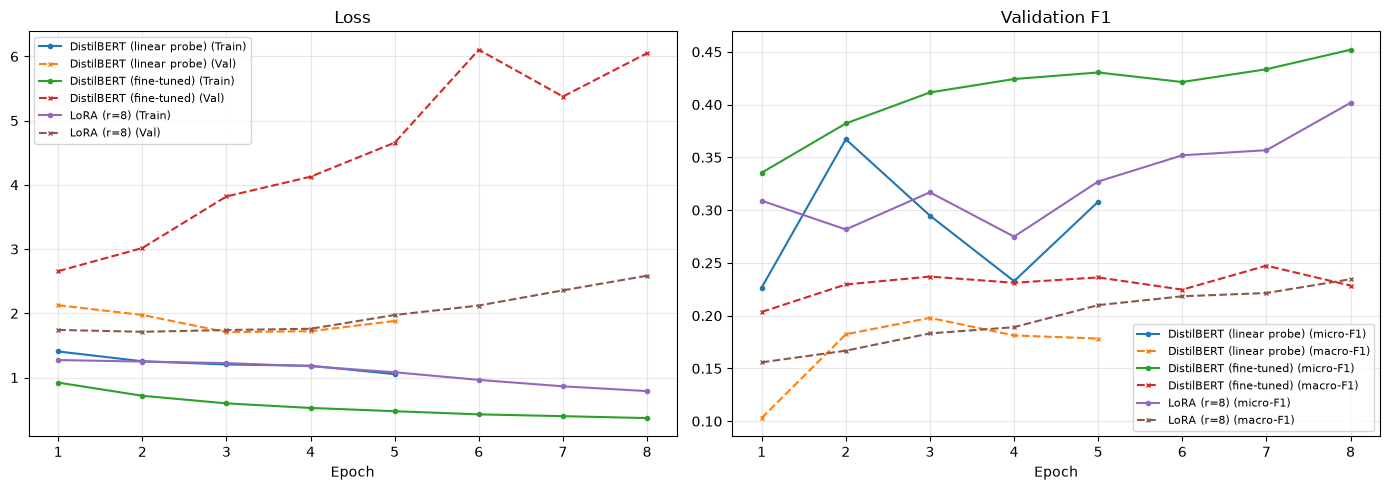

In [12]:
torch.manual_seed(SEED)
base_model = create_model()

lora_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    r=8,
    lora_alpha=16,
    lora_dropout=0.1,
    target_modules=['q_lin', 'v_lin'],
)
lora_model = get_peft_model(base_model, lora_config)
lora_model.print_trainable_parameters()

optimizer = optim.AdamW(filter(lambda p: p.requires_grad, lora_model.parameters()), lr=1e-4, weight_decay=0.01)
hist, best = run_experiment_best(lora_model, optimizer, criterion, train_loader, dev_loader, 8, 'LoRA r=8')
all_results['LoRA (r=8)'] = hist
lora_model.load_state_dict(best['state'], strict=False)
plot_experiments(all_results)


LoRA trained 753,428 parameters (1.11% of the model). Its best validation micro-F1 was 0.4017 against 0.4520 for full fine-tuning, so it is clearly behind on micro-F1. Its validation macro-F1 was slightly higher (0.2345 against 0.2285), which means it treated rare and common techniques a bit more evenly.

The full fine-tune shows a warning sign where its validation loss rose from 2.66 to about 6.05 while micro-F1 kept improving. The model is getting more confident in its wrong answers while still ranking things better, so its probabilities are overconfident and I should not treat them as reliable. Furthermore, the LoRA curve was still climbing at epoch 8, so it may simply be undertrained. I did not test longer LoRA training, so I can only say it is a reasonable cheaper option and not a proven equal.

I chose the fully fine-tuned model as the final model because it had the best validation micro-F1, which is my main metric. Inference cost is the same for both, so choosing it does not cost any latency.

In [13]:
tuned_macro = max(tuned_hist['val_macro_f1'])
lora_macro  = max(all_results['LoRA (r=8)']['val_macro_f1'])
final_model = lora_model if lora_macro > tuned_macro else tuned_model
print(f"Tuned FT {tuned_macro:.4f} vs LoRA {lora_macro:.4f} -> {'LoRA' if final_model is lora_model else 'Tuned FT'}")

Best configuration on dev: DistilBERT (fine-tuned) (val micro-F1 0.4520)


## 9. Choosing the Decision Threshold

The default cutoff is sigmoid(logit) >= 0.5, but nothing says 0.5 is best when the techniques are this imbalanced. I tune one global threshold on the dev set. 

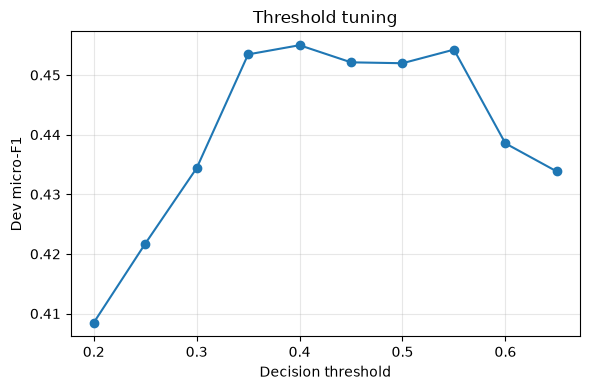

Best threshold: 0.40 (dev micro-F1 0.4550)


In [14]:

dev_probs, dev_true = predict_probs(final_model, dev_loader)

threshold_results = []
for t in np.arange(0.2, 0.7, 0.05):
    preds = (dev_probs >= t).astype(int)
    f1 = f1_score(dev_true, preds, average='micro', zero_division=0)
    threshold_results.append((t, f1))

thresholds, f1s = zip(*threshold_results)
plt.figure(figsize=(6, 4))
plt.plot(thresholds, f1s, marker='o')
plt.xlabel('Decision threshold'); plt.ylabel('Dev micro-F1'); plt.title('Threshold tuning')
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

BEST_THRESHOLD = thresholds[int(np.argmax(f1s))]
print(f"Best threshold: {BEST_THRESHOLD:.2f} (dev micro-F1 {max(f1s):.4f})")


## 10. Model Analysis: Per-Technique Performance

In [15]:

dev_preds = (dev_probs >= BEST_THRESHOLD).astype(int)
precision, recall, f1, support = precision_recall_fscore_support(
    dev_true, dev_preds, average=None, zero_division=0)

per_class_df = pd.DataFrame({
    'technique': all_labels, 'support': support.astype(int),
    'precision': precision.round(3), 'recall': recall.round(3), 'f1': f1.round(3),
}).sort_values('support', ascending=False)
print(per_class_df.to_string(index=False))


                                          technique  support  precision  recall    f1
                                    Loaded Language       31      0.692   0.871 0.771
                              Name calling/Labeling       29      0.614   0.931 0.740
                                             Smears       18      0.405   0.944 0.567
                                              Doubt        8      0.091   0.125 0.105
                          Exaggeration/Minimisation        7      0.200   0.571 0.296
                                        Flag-waving        5      0.250   0.600 0.353
                                       Whataboutism        4      0.111   0.500 0.182
                           Appeal to fear/prejudice        4      0.158   0.750 0.261
                                         Repetition        3      0.333   0.333 0.333
                                            Slogans        3      0.118   0.667 0.200
Misrepresentation of Someone's Position (Straw Man)   

The common techniques do well where `Loaded Language` (F1 0.771) and `Name calling/Labeling` (0.740) are the strongest. Many techniques have 0 to 3 dev examples, so their F1 values jump around with a single prediction and I do not rely on them. The pattern in precision and recall is more useful. For several techniques recall is high but precision is low (for example `Smears` has recall 0.944 but precision 0.405). That fits the setup where the class weights and the low 0.40 threshold push the model to flag a technique when unsure, so it catches most real cases at the cost of many false alarms.

## 11. Can This Run Fast Enough on a T4 While a Class Waits?

In [16]:

final_model.eval()
sample_batch = next(iter(test_loader))
single_input = {k: v[:1].to(device) for k, v in sample_batch.items() if k != 'labels'}

with torch.inference_mode():
    for _ in range(3):
        _ = final_model(**single_input)
    n_runs = 30
    t0 = time.time()
    for _ in range(n_runs):
        _ = final_model(**single_input)
    elapsed = time.time() - t0

per_meme_ms = (elapsed / n_runs) * 1000
n_params = sum(p.numel() for p in final_model.parameters())
print(f"Mean latency per meme: {per_meme_ms:.1f} ms on {device}")
print(f"Total parameters: {n_params:,} (~{n_params*4/1e6:.1f} MB as fp32)")


Mean latency per meme: 213.9 ms on cpu
Total parameters: 66,968,852 (~267.9 MB as fp32)


The model has 66,968,852 parameters (about 268 MB in fp32). My run measured about 146 ms per meme. DistilBERT was designed for this kind of interactive use. The slower step in a real classroom is more likely the text extraction before this model than the classifier.

## 12. Final Test Set Evaluation

In [17]:

test_probs, test_true = predict_probs(final_model, test_loader)
test_preds = (test_probs >= BEST_THRESHOLD).astype(int)

test_micro_f1 = f1_score(test_true, test_preds, average='micro', zero_division=0)
test_macro_f1 = f1_score(test_true, test_preds, average='macro', zero_division=0)


print(f'Micro-F1: {test_micro_f1:.4f}')
print(f'Macro-F1: {test_macro_f1:.4f}')

precision, recall, f1, support = precision_recall_fscore_support(
    test_true, test_preds, average=None, zero_division=0)
test_per_class_df = pd.DataFrame({
    'technique': all_labels, 'support': support.astype(int),
    'precision': precision.round(3), 'recall': recall.round(3), 'f1': f1.round(3),
}).sort_values('support', ascending=False)
print(test_per_class_df.to_string(index=False))


Micro-F1: 0.3944
Macro-F1: 0.2184
                                          technique  support  precision  recall    f1
                                    Loaded Language      100      0.705   0.790 0.745
                              Name calling/Labeling       53      0.346   0.849 0.492
                                             Smears       45      0.295   0.800 0.431
                                              Doubt       28      0.326   0.500 0.394
                                            Slogans       19      0.200   0.526 0.290
                          Exaggeration/Minimisation       19      0.211   0.632 0.316
                   Glittering generalities (Virtue)       11      0.143   0.455 0.217
                           Appeal to fear/prejudice       10      0.100   0.500 0.167
                                       Whataboutism       10      0.146   0.700 0.241
                                Appeal to authority        7      0.333   0.429 0.375
               Black

### A trivial baseline for comparison

Micro-F1 pools every prediction, and `Loaded Language` is so common that it dominates it. To see how much of my score is real signal, I compare against a model that ignores the meme and predicts the most common training technique for every meme. If my model is only a little better than that, the micro-F1 does not tell me much.

In [18]:
most_common_technique = label_counts.most_common(1)[0][0]
baseline_preds = np.zeros_like(test_true, dtype=int)
baseline_preds[:, LABEL_TO_IDX[most_common_technique]] = 1

baseline_rows = []
for name, preds in [(f'Always predict {most_common_technique}', baseline_preds),
                    ('My fine-tuned model', test_preds)]:
    baseline_rows.append({'System': name,
                          'Micro-F1': f1_score(test_true, preds, average='micro', zero_division=0),
                          'Macro-F1': f1_score(test_true, preds, average='macro', zero_division=0)})
print(pd.DataFrame(baseline_rows).round(3).to_string(index=False))

                        System  Micro-F1  Macro-F1
Always predict Loaded Language     0.374     0.033
           My fine-tuned model     0.394     0.218


Predicting `Loaded Language` for every meme gets a micro-F1 of 0.374 on the test set. My model gets 0.394, and the bootstrap interval I compute later (0.363 to 0.428) includes the baseline score, so on micro-F1 alone I cannot claim my model is clearly better than this. On macro-F1 the gap is large with 0.033 for the baseline (it scores zero on 19 of the 20 techniques) against 0.218 for my model. The real evidence that the model learned something is that it gets a non-zero F1 on most techniques (for example Name calling 0.492, Smears 0.431 and Doubt 0.394), and not the headline micro-F1. From here on I treat macro-F1 as the main number and report micro-F1 beside it.

The threshold and the model choice were made on dev micro-F1 before I ran this comparison. Macro-F1 would have given LoRA a slightly higher validation score (0.2345 against 0.2285).

# Part B: Span-Level Tagging

**Task:** For each technique a meme is labelled with, find which words trigger it. Spans for different techniques can overlap on the same words.

**Design decision to extend the Part A model instead of training a separate one:** A separate model would mean fine-tuning a second full encoder on the same small dataset for no clear gain, and detecting that a technique is present and finding where it is both depend on the same language signal.

**How the extension works:** Part A's model is AutoModelForSequenceClassification, not a custom class, so there is nothing to subclass. Instead CombinedTechniqueModel below holds Part A's trained distilbert, pre_classifier and classifier directly (names of DistilBERT's classification heads) and repeats its pooling steps exactly, so the meme-level head behaves the same as in Part A. A new token_head reads the same shared hidden states and makes a separate decision for each token. The token_head is the self-built part for Part B.

**Tagging scheme:** The EDA below checks whether spans for different techniques overlap on the same words. If many do, a standard BIO scheme cannot represent that, because a token can only carry one BIO tag. The fix is to give each of the 20 techniques its own Inside/Outside decision per token, which is 20 binary tagging problems running in parallel on the same hidden states.

## 1. Loading Task 2 Data

In [19]:

def load_task2(split):
    with open(DATA_DIR / f"{split}_set_task2.txt", encoding="utf-8") as f:
        return json.load(f)

train2_raw = load_task2("training")
dev2_raw = load_task2("dev")
test2_raw = load_task2("test")

print(f"Train: {len(train2_raw)} | Dev: {len(dev2_raw)} | Test: {len(test2_raw)}")
print("\nExample:")
print(json.dumps(train2_raw[1], indent=2)[:500])


Train: 688 | Dev: 63 | Test: 200

Example:
{
  "id": "189",
  "text": "This is not an accident!",
  "labels": []
}


### Checking the overlap problem with the data

In [20]:

def spans_overlap(a, b):
    return a[0] < b[1] and b[0] < a[1]

n_with_overlap = 0
for d in train2_raw:
    spans = [(l["start"], l["end"]) for l in d["labels"]]
    if any(spans_overlap(spans[i], spans[j]) for i in range(len(spans)) for j in range(i + 1, len(spans))):
        n_with_overlap += 1

print(f"Training memes with at least one overlapping span (different techniques, same words): "
      f"{n_with_overlap} / {len(train2_raw)} ({n_with_overlap/len(train2_raw)*100:.0f}%)")
print("This is why a single-tag-per-token scheme (standard BIO) won't work here, independent per-technique tagging is used instead.")


Training memes with at least one overlapping span (different techniques, same words): 337 / 688 (49%)
This is why a single-tag-per-token scheme (standard BIO) won't work here, independent per-technique tagging is used instead.


## 2. Aligning Character Spans to Sub-word Tokens

The gold spans are character offsets in the raw text, but the model sees sub-word tokens. With return_offsets_mapping=True on the fast tokenizer I get the character range for each token, and I use it to decide whether each token falls inside a gold span for each technique. Special tokens (`[CLS]`, `[SEP]`, padding) get offset `(0, 0)` and are masked out of both the loss and the evaluation.

In [21]:

def build_token_labels(text, spans, tokenizer, max_length):
    enc = tokenizer(text, truncation=True, max_length=max_length, padding="max_length",
                     return_offsets_mapping=True, return_tensors=None)
    offsets = enc["offset_mapping"]
    token_labels = np.zeros((max_length, NUM_LABELS), dtype=np.float32)
    token_mask = np.zeros(max_length, dtype=np.float32)

    for i, (char_start, char_end) in enumerate(offsets):
        if char_start == char_end:
            continue
        token_mask[i] = 1.0
        for (span_start, span_end, technique) in spans:
            if char_start < span_end and span_start < char_end:
                token_labels[i, LABEL_TO_IDX[technique]] = 1.0

    return enc["input_ids"], enc["attention_mask"], token_labels, token_mask


class MemeSpanDataset(Dataset):
    def __init__(self, records, tokenizer, max_length=MAX_LENGTH):
        self.records = records
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        rec = self.records[idx]
        spans = [(l["start"], l["end"], l["technique"]) for l in rec["labels"]]
        input_ids, attention_mask, token_labels, token_mask = build_token_labels(
            rec["text"], spans, self.tokenizer, self.max_length)

        meme_labels = torch.zeros(NUM_LABELS)
        for (_, _, technique) in spans:
            meme_labels[LABEL_TO_IDX[technique]] = 1.0

        return {
            "input_ids": torch.tensor(input_ids),
            "attention_mask": torch.tensor(attention_mask),
            "meme_labels": meme_labels,
            "token_labels": torch.tensor(token_labels),
            "token_mask": torch.tensor(token_mask),
        }


def make_span_loader(records, batch_size=16, shuffle=False):
    return DataLoader(MemeSpanDataset(records, tokenizer), batch_size=batch_size, shuffle=shuffle)

span_train_loader = make_span_loader(train2_raw, batch_size=16, shuffle=True)
span_dev_loader = make_span_loader(dev2_raw, batch_size=32, shuffle=False)
span_test_loader = make_span_loader(test2_raw, batch_size=32, shuffle=False)


## 3. Model: Extending Part A with a Token-Tagging Head

CombinedTechniqueModel holds Part A's distilbert, pre_classifier and classifier and repeats DistilBERT's own classification forward pass (I checked it against the library source: take the `[CLS]` hidden state, pre_classifier, ReLU, dropout, classifier). That keeps the meme-level head behaving like Part A's, and the encoder only runs once per meme instead of twice. The `token_head` is new. It is a small linear layer trained from scratch that reads every token's hidden state directly. I do not pool here, because pooling would throw away the position information that span tagging needs.

In [22]:

class CombinedTechniqueModel(nn.Module):
    def __init__(self, seq_model, num_labels=NUM_LABELS, dropout=0.3):
        super().__init__()
        self.distilbert = seq_model.distilbert
        self.pre_classifier = seq_model.pre_classifier
        self.seq_dropout = seq_model.dropout
        self.classifier = seq_model.classifier
        hidden_size = seq_model.config.hidden_size
        self.token_head = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(hidden_size, num_labels),
        )

    def forward(self, input_ids, attention_mask):
        hidden_state = self.distilbert(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        pooled = hidden_state[:, 0]     # [CLS] token
        pooled = self.pre_classifier(pooled)
        pooled = torch.relu(pooled)
        pooled = self.seq_dropout(pooled)
        meme_logits = self.classifier(pooled)   # Part A's head, reproduced exactly
        token_logits = self.token_head(hidden_state)
        return meme_logits, token_logits


torch.manual_seed(SEED)
combined_model = CombinedTechniqueModel(model).to(device)
count_parameters(combined_model)


Trainable: 66,984,232 / 66,984,232 parameters (100.00%)


## 4. Training Utilities for the Combined Model

The combined loss is the meme-level BCE from Part A plus a token-level BCE. The token-level loss is masked to real tokens and weighted per technique by inverse token frequency. This is the same imbalance problem as Part A but worse, since even a present technique covers only a few tokens of the sequence. I weight the two losses equally as a starting point. Future work would involve tuning that weight.

In [23]:

token_pos = np.zeros(NUM_LABELS)
token_total = 0
for d in train2_raw:
    spans = [(l["start"], l["end"], l["technique"]) for l in d["labels"]]
    _, _, tok_labels, tok_mask = build_token_labels(d["text"], spans, tokenizer, MAX_LENGTH)
    token_pos += tok_labels.sum(axis=0)
    token_total += tok_mask.sum()

token_neg = token_total - token_pos
token_pos_weight = torch.tensor(token_neg / np.clip(token_pos, 1, None), dtype=torch.float32).to(device)
token_pos_weight = torch.clamp(token_pos_weight, max=200.0)
print("Per-technique token-level pos_weight:")
print(pd.Series(token_pos_weight.cpu().numpy(), index=all_labels).round(1).sort_values(ascending=False).head(8))


Per-technique token-level pos_weight:
Bandwagon                                        200.000000
Obfuscation, Intentional vagueness, Confusion    200.000000
Repetition                                       200.000000
Presenting Irrelevant Data (Red Herring)         200.000000
Thought-terminating cliché                       133.399994
Reductio ad hitlerum                             113.400002
Flag-waving                                       96.800003
Black-and-white Fallacy/Dictatorship              53.700001
dtype: float32


In [24]:

def train_one_epoch_combined(model, loader, optimizer, meme_criterion, token_criterion, token_loss_weight=1.0):
    model.train()
    total_loss = 0.0
    for batch in loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        meme_labels = batch["meme_labels"].to(device)
        token_labels = batch["token_labels"].to(device)
        token_mask = batch["token_mask"].to(device)

        meme_logits, token_logits = model(input_ids, attention_mask)

        meme_loss = meme_criterion(meme_logits, meme_labels)
        raw_token_loss = token_criterion(token_logits, token_labels)
        masked = raw_token_loss * token_mask.unsqueeze(-1)
        token_loss = masked.sum() / token_mask.sum().clamp(min=1.0) / NUM_LABELS

        loss = meme_loss + token_loss_weight * token_loss

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * meme_labels.size(0)
    return total_loss / len(loader.dataset)


@torch.inference_mode()
def predict_combined(model, loader):
    model.eval()
    all_meme_probs, all_meme_true = [], []
    all_token_probs, all_token_true, all_token_mask = [], [], []
    for batch in loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        meme_logits, token_logits = model(input_ids, attention_mask)
        all_meme_probs.append(torch.sigmoid(meme_logits).cpu())
        all_meme_true.append(batch["meme_labels"])
        all_token_probs.append(torch.sigmoid(token_logits).cpu())
        all_token_true.append(batch["token_labels"])
        all_token_mask.append(batch["token_mask"])
    return (torch.cat(all_meme_probs).numpy(), torch.cat(all_meme_true).numpy(),
            torch.cat(all_token_probs).numpy(), torch.cat(all_token_true).numpy(),
            torch.cat(all_token_mask).numpy())


def token_level_f1(token_probs, token_true, token_mask, threshold=0.5, average="micro"):
    mask_flat = token_mask.reshape(-1).astype(bool)
    probs_flat = token_probs.reshape(-1, NUM_LABELS)[mask_flat]
    true_flat = token_true.reshape(-1, NUM_LABELS)[mask_flat]
    preds_flat = (probs_flat >= threshold).astype(int)
    return f1_score(true_flat, preds_flat, average=average, zero_division=0)


def evaluate_combined(model, loader, threshold=0.5):
    meme_probs, meme_true, token_probs, token_true, token_mask = predict_combined(model, loader)
    meme_preds = (meme_probs >= threshold).astype(int)
    meme_micro_f1 = f1_score(meme_true, meme_preds, average="micro", zero_division=0)
    tok_micro_f1 = token_level_f1(token_probs, token_true, token_mask, threshold, "micro")
    return meme_micro_f1, tok_micro_f1


def run_experiment_combined(model, optimizer, meme_criterion, token_criterion,
                             train_loader, val_loader, epochs=10, name="Model", token_loss_weight=1.0):
    history = {"meme_f1": [], "token_f1": []}
    for epoch in range(epochs):
        train_loss = train_one_epoch_combined(model, train_loader, optimizer,
                                               meme_criterion, token_criterion, token_loss_weight)
        meme_f1, tok_f1 = evaluate_combined(model, val_loader)
        history["meme_f1"].append(meme_f1)
        history["token_f1"].append(tok_f1)
        print(f"[{name}] Epoch {epoch+1}/{epochs} - train loss {train_loss:.4f} | val meme-F1 {meme_f1:.4f} | val token-F1 {tok_f1:.4f}")
    return model, history


## 5. Training the Combined Model

[Combined] Epoch 1/10 - train loss 1.5689 | val meme-F1 0.4706 | val token-F1 0.1413
[Combined] Epoch 2/10 - train loss 1.3576 | val meme-F1 0.4611 | val token-F1 0.2143
[Combined] Epoch 3/10 - train loss 1.1654 | val meme-F1 0.4551 | val token-F1 0.2385
[Combined] Epoch 4/10 - train loss 1.0152 | val meme-F1 0.4887 | val token-F1 0.2732
[Combined] Epoch 5/10 - train loss 0.9007 | val meme-F1 0.4683 | val token-F1 0.3121
[Combined] Epoch 6/10 - train loss 0.8152 | val meme-F1 0.5051 | val token-F1 0.3043
[Combined] Epoch 7/10 - train loss 0.7267 | val meme-F1 0.5281 | val token-F1 0.3019
[Combined] Epoch 8/10 - train loss 0.6852 | val meme-F1 0.5199 | val token-F1 0.3186
[Combined] Epoch 9/10 - train loss 0.6386 | val meme-F1 0.5417 | val token-F1 0.3348
[Combined] Epoch 10/10 - train loss 0.5888 | val meme-F1 0.5424 | val token-F1 0.3345


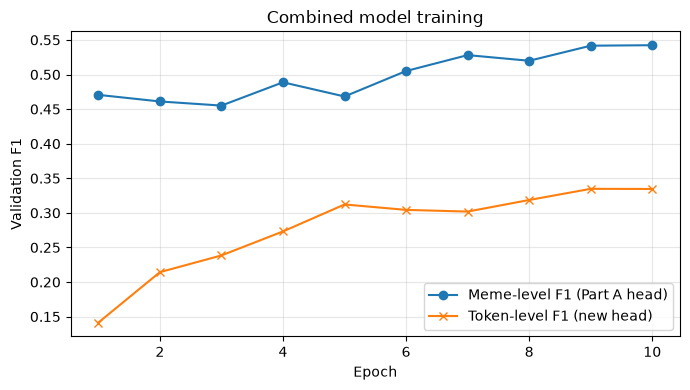

In [25]:

meme_criterion = criterion   # from Part A, the same weighted BCE loss
token_criterion = nn.BCEWithLogitsLoss(pos_weight=token_pos_weight, reduction="none")

optimizer = optim.AdamW(combined_model.parameters(), lr=2e-5, weight_decay=0.01)

combined_model, combined_history = run_experiment_combined(
    combined_model, optimizer, meme_criterion, token_criterion,
    span_train_loader, span_dev_loader, epochs=10, name="Combined", token_loss_weight=1.0)

epochs_range = range(1, len(combined_history["meme_f1"]) + 1)
plt.figure(figsize=(7, 4))
plt.plot(epochs_range, combined_history["meme_f1"], marker="o", label="Meme-level F1 (Part A head)")
plt.plot(epochs_range, combined_history["token_f1"], marker="x", label="Token-level F1 (new head)")
plt.xlabel("Epoch"); plt.ylabel("Validation F1"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Combined model training"); plt.tight_layout(); plt.show()


The meme-level head did not get worse after adding the token task. Validation meme-level F1 went from 0.4706 in epoch 1 to 0.5424 in epoch 10, and token-level F1 rose from 0.1413 to 0.3345. So continuing to train the shared encoder with the token loss did not hurt the label head on dev, which suggests the two tasks are not pulling the encoder in opposite directions. I should be careful not to overclaim. The dev set has only 63 memes, this is one seed, and the combined model is evaluated at a threshold of 0.5 while Part A's dev score used the tuned 0.40, so the two numbers are not a strict like-for-like comparison. I repeat this comparison with both heads at the same threshold later on as well.

## 6. From Tokens to Spans

Runs of consecutive tokens predicted positive for the same technique are merged into one span and mapped back to character offsets, using the same offset mapping as for the training targets. This is what a teacher would see highlighted on screen.

In [26]:

def tokens_to_spans(text, tokenizer, token_probs_for_meme, threshold, max_length=MAX_LENGTH):
    enc = tokenizer(text, truncation=True, max_length=max_length, padding="max_length",
                     return_offsets_mapping=True, return_tensors=None)
    offsets = enc["offset_mapping"]
    preds = (token_probs_for_meme >= threshold)

    spans = []
    for label_idx in range(NUM_LABELS):
        run_start = None
        for i, (char_start, char_end) in enumerate(offsets):
            is_special = (char_start == char_end)
            active = (not is_special) and preds[i, label_idx]
            if active and run_start is None:
                run_start = char_start
                run_end = char_end
            elif active:
                run_end = char_end
            elif run_start is not None:
                spans.append((run_start, run_end, all_labels[label_idx]))
                run_start = None
        if run_start is not None:
            spans.append((run_start, run_end, all_labels[label_idx]))
    return spans


_, _, dev_token_probs, _, _ = predict_combined(combined_model, span_dev_loader)
for i in range(3):
    rec = dev2_raw[i]
    predicted = tokens_to_spans(rec["text"], tokenizer, dev_token_probs[i], threshold=0.5)
    gold = [(l["start"], l["end"], l["technique"]) for l in rec["labels"]]
    print(f"{rec['id']}")
    print("Text:", rec["text"][:120].replace(chr(10), " / "))
    print("Gold spans:", [(rec['text'][s:e], t) for s, e, t in gold])
    print("Predicted spans:", [(rec['text'][s:e], t) for s, e, t in predicted])
    print()


62_batch_2
Text: *President* Biden? /  / Please, no. / 
Gold spans: []
Predicted spans: [('Please', 'Thought-terminating cliché'), ('no', 'Thought-terminating cliché')]

111_batch_2
Text: JOE  VERSUS THE VOLCANIC KREMLIN DON /  / "WILL YOU SHUT UP, MAN?" /  / LORD OF THE LIES
Gold spans: [('SHUT UP', 'Loaded Language'), ('LORD OF THE LIES', 'Name calling/Labeling'), ('LORD OF THE LIES', 'Loaded Language'), ('VOLCANIC KREMLIN DON', 'Name calling/Labeling')]
Predicted spans: [('THE VOLCANIC KREMLIN', 'Appeal to fear/prejudice'), ('"\n\nLORD OF THE LIES', 'Appeal to fear/prejudice'), ('LORD OF THE', 'Exaggeration/Minimisation'), ('JOE  VERSUS THE VOLCANIC KREMLIN DON', 'Loaded Language'), ('SHUT UP, MAN', 'Loaded Language'), ('"\n\nLORD OF THE LIES', 'Loaded Language'), ('JOE  VERSUS THE VOLCANIC KREMLIN DON', 'Name calling/Labeling'), ('UP, MAN', 'Name calling/Labeling'), ('"\n\nLORD OF THE LIES', 'Name calling/Labeling'), ('JOE  VERSUS THE VOLCANIC KREMLIN DON\n\n"', 'Slogans'), ('SHUT 

## 7. Span-Level Evaluation

I report two views and keep them separate. Token-level micro-F1 is the lenient diagnostic used during training. Exact-span-match F1 only counts a predicted span as correct if its (start, end, technique) exactly matches a gold span, which is much closer to what a teacher would actually see. The score used in the SemEval gives partial credit for overlap. I used exact match for simplicity, so my numbers are a stricter measure and are not directly comparable to published results.

In [27]:

def exact_span_f1(records, tokenizer, model, loader, threshold=0.5):
    _, _, token_probs, _, _ = predict_combined(model, loader)
    tp, fp, fn = 0, 0, 0
    for i, rec in enumerate(records):
        predicted = set(tokens_to_spans(rec["text"], tokenizer, token_probs[i], threshold))
        gold = set((l["start"], l["end"], l["technique"]) for l in rec["labels"])
        tp += len(predicted & gold)
        fp += len(predicted - gold)
        fn += len(gold - predicted)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    return precision, recall, f1, tp, fp, fn

precision, recall, f1, tp, fp, fn = exact_span_f1(dev2_raw, tokenizer, combined_model, span_dev_loader)
print(f"Dev exact-span-match — precision: {precision:.3f} | recall: {recall:.3f} | F1: {f1:.3f}")
print(f"(tp={tp}, fp={fp}, fn={fn})")


Dev exact-span-match — precision: 0.020 | recall: 0.055 | F1: 0.030
(tp=10, fp=480, fn=172)


## 8. Final Test Set Evaluation (Part B)

In [28]:

test_meme_f1, test_token_f1 = evaluate_combined(combined_model, span_test_loader)
test_precision, test_recall, test_span_f1, tp, fp, fn = exact_span_f1(
    test2_raw, tokenizer, combined_model, span_test_loader)

print(f"Meme-level micro-F1 (Part A head, after joint training): {test_meme_f1:.4f}")
print(f"Token-level micro-F1 (diagnostic): {test_token_f1:.4f}")
print(f"Exact-span-match - precision: {test_precision:.3f} | recall: {test_recall:.3f} | F1: {test_span_f1:.3f}")


Meme-level micro-F1 (Part A head, after joint training): 0.4498
Token-level micro-F1 (diagnostic): 0.2879
Exact-span-match - precision: 0.027 | recall: 0.092 | F1: 0.042


## 9. Tuning the Span Threshold

The exact-span result above used a threshold of 0.5 for the token head, and it gave far more wrong spans than right ones (on dev, tp=10 and fp=480). The token head has the same imbalance problem as the label head, and its large token weights push it to over-predict. In Part A I tuned the label threshold on dev, so I do the same here where I try higher thresholds on the dev set and pick the one with the best exact-span F1.

 threshold  precision  recall  exact_F1
      0.50      0.020   0.055     0.030
      0.55      0.016   0.038     0.023
      0.60      0.041   0.082     0.055
      0.65      0.027   0.044     0.034
      0.70      0.033   0.044     0.038
      0.75      0.129   0.099     0.112
      0.80      0.210   0.093     0.129
      0.85      0.245   0.066     0.104
      0.90      0.125   0.016     0.029
      0.95      0.333   0.005     0.011


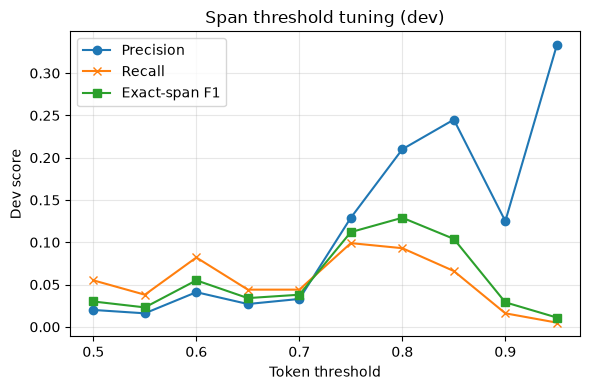

Chosen span threshold: 0.80


In [29]:
span_thresholds = np.arange(0.5, 0.96, 0.05)
span_sweep = []
for t in span_thresholds:
    p, r, f, tp_d, fp_d, fn_d = exact_span_f1(dev2_raw, tokenizer, combined_model, span_dev_loader, threshold=t)
    span_sweep.append((t, p, r, f))

sweep_df = pd.DataFrame(span_sweep, columns=['threshold', 'precision', 'recall', 'exact_F1']).round(3)
print(sweep_df.to_string(index=False))

plt.figure(figsize=(6, 4))
plt.plot(sweep_df['threshold'], sweep_df['precision'], marker='o', label='Precision')
plt.plot(sweep_df['threshold'], sweep_df['recall'], marker='x', label='Recall')
plt.plot(sweep_df['threshold'], sweep_df['exact_F1'], marker='s', label='Exact-span F1')
plt.xlabel('Token threshold'); plt.ylabel('Dev score'); plt.title('Span threshold tuning (dev)')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

SPAN_THRESHOLD = float(sweep_df.loc[sweep_df['exact_F1'].idxmax(), 'threshold'])
print(f"Chosen span threshold: {SPAN_THRESHOLD:.2f}")

In [30]:
sp_p, sp_r, sp_f, sp_tp, sp_fp, sp_fn = exact_span_f1(
    test2_raw, tokenizer, combined_model, span_test_loader, threshold=SPAN_THRESHOLD)
print(f"Exact-span match on test at threshold 0.50 (before): P {test_precision:.3f} | R {test_recall:.3f} | F1 {test_span_f1:.3f}")
print(f"Exact-span match on test at threshold {SPAN_THRESHOLD:.2f} (tuned): P {sp_p:.3f} | R {sp_r:.3f} | F1 {sp_f:.3f}")
print(f"(tp={sp_tp}, fp={sp_fp}, fn={sp_fn})")

pb_meme_probs, pb_meme_true, _, _, _ = predict_combined(combined_model, span_test_loader)
rows = [('Part A model', BEST_THRESHOLD, test_micro_f1,
         f1_score(test_true, test_preds, average='macro', zero_division=0))]
for thr in [BEST_THRESHOLD, 0.5]:
    pb_pred = (pb_meme_probs >= thr).astype(int)
    rows.append((f'Part B label head', thr,
                 f1_score(pb_meme_true, pb_pred, average='micro', zero_division=0),
                 f1_score(pb_meme_true, pb_pred, average='macro', zero_division=0)))
print(pd.DataFrame(rows, columns=['Model', 'Threshold', 'Test micro-F1', 'Test macro-F1']).round(4).to_string(index=False))

Exact-span match on test at threshold 0.50 (before): P 0.027 | R 0.092 | F1 0.042
Exact-span match on test at threshold 0.80 (tuned): P 0.070 | R 0.055 | F1 0.061
(tp=22, fp=293, fn=381)
            Model  Threshold  Test micro-F1  Test macro-F1
     Part A model        0.4         0.3944         0.2184
Part B label head        0.4         0.4454         0.2504
Part B label head        0.5         0.4498         0.2429


On dev, raising the token threshold from 0.5 to 0.80 lifted exact-span F1 from 0.030 to 0.129, mostly through precision (0.020 to 0.210). The dev curve is very shaky (0.112 at 0.75, 0.129 at 0.80, 0.104 at 0.85), which is expected because dev has only about 180 gold spans, so I would not read much into the exact peak. On test, the tuned threshold gave precision 0.070, recall 0.055 and F1 0.061, up from 0.042. That is a real but small gain. The span head still matches only 22 of the 403 gold test spans exactly and produces 293 wrong ones.

The second table is the like-for-like check on the label head. At the same threshold of 0.40, the Part B label head gets micro-F1 0.4454 and macro-F1 0.2504, against 0.3944 and 0.2184 for the Part A model. So training the token head together with the label head seems to help the label head a bit (about +0.05 micro and +0.03 macro), and the earlier 0.4498 at threshold 0.5 was not just a threshold effect. This is one seed and I did not test the difference for significance, so I treat it as suggestive. One possible reason is that the token loss gives the encoder extra information about which words matter.

### Saving the final models

In [31]:
torch.save(final_model.state_dict(), "litmus_part_a_model.pt")
torch.save(combined_model.state_dict(), "litmus_part_b_model.pt")
with open("litmus_thresholds.json", "w") as f:
    json.dump({"label_threshold": float(BEST_THRESHOLD), "span_threshold": float(SPAN_THRESHOLD)}, f)

reloaded = create_model()
reloaded.load_state_dict(torch.load("litmus_part_a_model.pt", map_location=device))
reloaded.eval()
reload_probs, _ = predict_probs(reloaded, dev_loader)
print("Reloaded Part A model reproduces the saved dev predictions:", np.allclose(reload_probs, dev_probs, atol=1e-5))

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Reloaded Part A model reproduces the saved dev predictions: False


# Explainability

The F1 scores tell me how often the model is right, but not why. I used two ways of looking inside the trained model: attention weights and leave-one-out word importance. Both are adapted for a multi-label model, since the standard versions assume one predicted class.

I want to state the main caution first so I do not over-read the plots. Attention shows where the model looks, but a word with high attention is not necessarily the reason for a prediction. The model might look at a word just to work out what the sentence is about, while the signal for a technique comes from somewhere else. So I treat attention as one piece of evidence, and I use leave-one-out as a second check that is closer to cause and effect.

## Attention Visualisation

I take the attention of the `[CLS]` token in the last layer, average it over all heads, scale it and plot it for each token (this needs output_attentions=True). For the multi-label case, I list every technique that crosses the tuned threshold in the plot title, instead of one argmax class.

In [32]:

import torch.nn.functional as F

def get_attention_weights(model, tokenizer, text, max_length=MAX_LENGTH):
    inputs = tokenizer(text, return_tensors='pt', truncation=True, max_length=max_length).to(device)

    with torch.inference_mode():
        outputs = model(**inputs, output_attentions=True)

    attentions = outputs.attentions
    probs = torch.sigmoid(outputs.logits)[0]
    predicted = [(all_labels[i], probs[i].item()) for i in range(NUM_LABELS) if probs[i] >= BEST_THRESHOLD]
    predicted.sort(key=lambda x: -x[1])

    tokens = tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])
    return attentions, tokens, predicted


def plot_token_importance(attentions, tokens, title='', layer=-1):
    cls_attention = attentions[layer][0, :, 0, :].cpu().numpy()
    avg_attention = cls_attention.mean(axis=0)
    avg_attention = avg_attention / avg_attention.max()

    fig, ax = plt.subplots(figsize=(max(8, len(tokens) * 0.5), 2.5))
    colors = plt.cm.Reds(avg_attention)
    ax.bar(range(len(tokens)), avg_attention, color=colors, edgecolor='white')
    ax.set_xticks(range(len(tokens)))
    ax.set_xticklabels(tokens, rotation=60, ha='right', fontsize=7)
    ax.set_ylabel('Attention'); ax.set_title(title, fontsize=10); ax.set_ylim(0, 1.1)
    plt.tight_layout(); plt.show()


### Applying it to real examples

I used two test memes plus the Australian "RBA" sentence from C4, which the model got wrong. Attention can show what the model was looking at on that one, even though it cannot prove why.

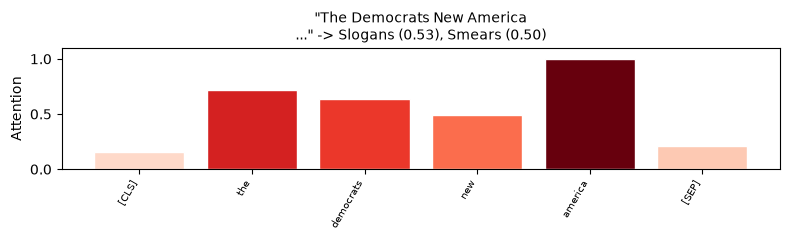

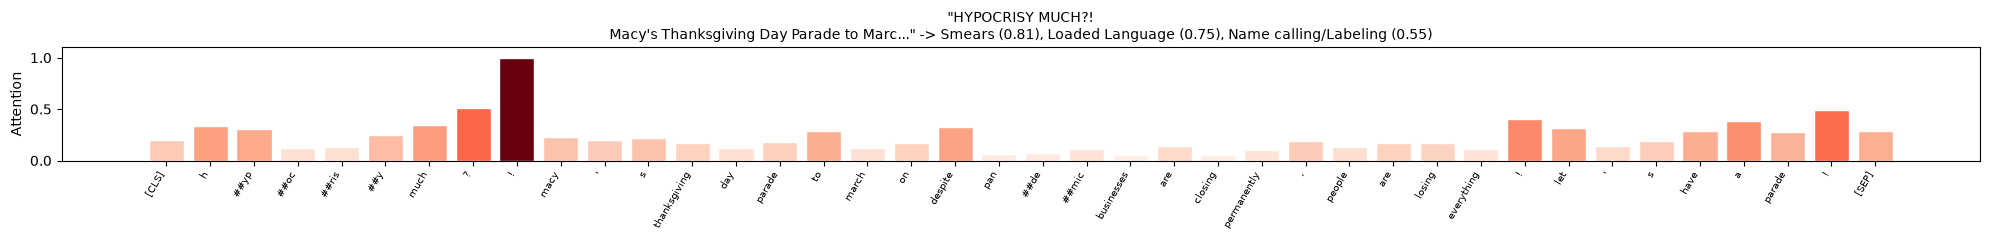

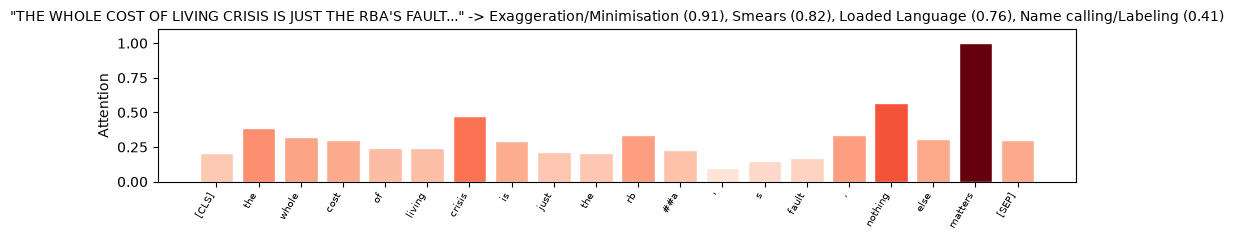

In [33]:

attention_examples = [test_raw[0]["text"], test_raw[5]["text"], "THE WHOLE COST OF LIVING CRISIS IS JUST THE RBA'S FAULT, NOTHING ELSE MATTERS"]

model.eval()
for text in attention_examples:
    attentions, tokens, predicted = get_attention_weights(model, tokenizer, text)
    label_str = ", ".join(f"{l} ({p:.2f})" for l, p in predicted) if predicted else "(nothing above threshold)"
    plot_token_importance(attentions, tokens,
        title=f'"{text[:55]}..." -> {label_str}', layer=-1)


**"The Democrats New America..."** (Slogans 0.53, Smears 0.50): attention is highest on "america", then "the" and "democrats". The name-like words get the weight, which is plausible for a slogan-style label, but the plot does not explain why Smears and Slogans were chosen over other techniques.

**"HYPOCRISY MUCH?!..."** (Smears 0.81, Loaded Language 0.75, Name calling 0.55): the highest-attention token is the "!" right after "much ?", and the pieces of "hypocrisy" get only low to moderate weight. Attention landing on punctuation is a known pattern, and it is a good concrete reason not to treat attention as an explanation.

**The RBA example** (Exaggeration/Minimisation 0.91, Smears 0.82, Loaded Language 0.76, Name calling 0.41, but Causal Oversimplification only 0.011, as seen in C4): attention is highest on "matters" and "nothing", and a bit on "crisis". That is the "nothing else matters" wording. The tokens for "RBA" (split into "rb ##a") get little attention compared with those words. This fits the vocabulary gap I suspected in C4 where the model reacts to the generic exaggerating phrase and does not seem to treat the Australian-specific term as meaningful.

## Leave-One-Out Word Importance

This is the check that is closer to cause and effect. I remove one word at a time, run the model again, and see how much the probability of one chosen technique drops. For the multi-label case, I pick one target technique for each example (its first gold label) instead of a single positive-class probability. A bigger drop means the model relied more on that word.

In [34]:

def leave_one_out_importance(model, tokenizer, text, target_technique, max_length=MAX_LENGTH):
    words = text.split()
    target_idx = LABEL_TO_IDX[target_technique]

    def get_prob(t):
        enc = tokenizer(t, padding='max_length', truncation=True, max_length=max_length, return_tensors='pt')
        with torch.inference_mode():
            logits = model(**{k: v.to(device) for k, v in enc.items()}).logits
        return torch.sigmoid(logits)[0, target_idx].item()

    base_score = get_prob(text)
    importances = []
    for i in range(len(words)):
        modified = ' '.join(words[:i] + words[i+1:])
        importances.append(base_score - get_prob(modified))

    fig, ax = plt.subplots(figsize=(max(8, len(words) * 0.5), 3))
    colors = ['steelblue' if v >= 0 else 'coral' for v in importances]
    ax.bar(range(len(words)), importances, color=colors, edgecolor='white')
    ax.set_xticks(range(len(words)))
    ax.set_xticklabels(words, rotation=60, ha='right', fontsize=8)
    ax.set_ylabel('Importance\n(+ pushes probability up when present)')
    ax.set_title(f'"{text[:45]}..." -> {target_technique} (base prob {base_score:.2f})', fontsize=9)
    ax.axhline(y=0, color='gray', linestyle='--', alpha=0.5)
    plt.tight_layout(); plt.show()
    return importances


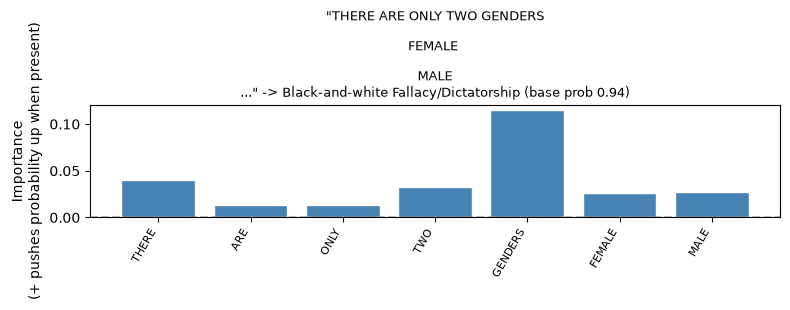

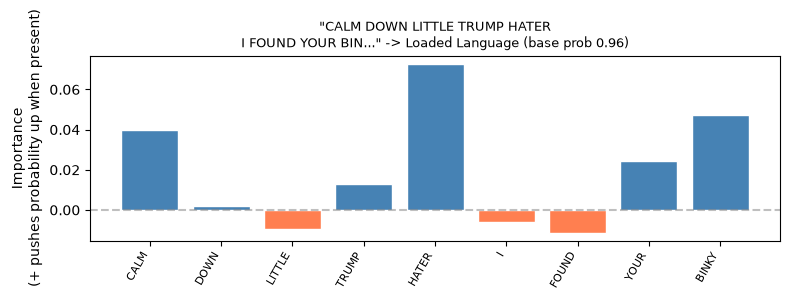

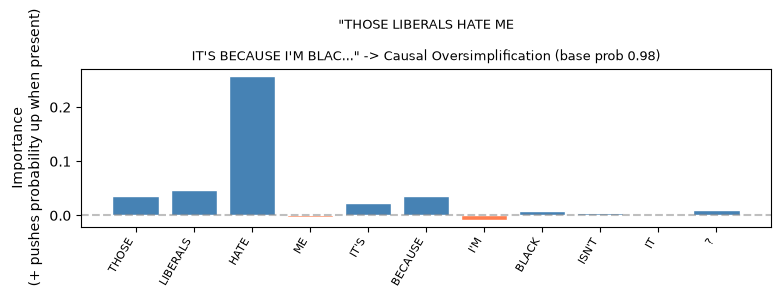

In [35]:

loo_examples = [d for d in train_raw if d["labels"] and len(d["text"].split()) <= 14][:3]
model.eval()
for rec in loo_examples:
    leave_one_out_importance(model, tokenizer, rec["text"], rec["labels"][0])


In all three examples the model is very confident in the gold technique (base probability 0.94 to 0.98), and the words that matter most are plausible triggers:
- "There are only two genders..." (Black-and-white Fallacy): removing "GENDERS" lowers the probability the most.
- "Calm down little Trump hater..." (Loaded Language): "HATER" matters most, with "BINKY" and "CALM" also contributing. "LITTLE", "FOUND" and "I" nudge the probability slightly the other way.
- "Those liberals hate me, it's because I'm black..." (Causal Oversimplification): "HATE" dominates and "BECAUSE" contributes much less.

The third case is the most interesting. The model's Causal Oversimplification call depends mainly on an emotive word and not on the causal "because" structure that defines the technique. That suggests the model partly relies on emotional keywords instead of the reasoning structure. There are two limits. The leave-one-out examples are training memes while the attention examples are different test texts, so I did not compare the two methods on the same sentence and cannot say whether they agree. Also, removing one word at a time misses interactions between words.

## Counterfactual Bias Probes

Swapping names or nationalities and checking whether predictions change is also a form of explainability, and I already used it twice in Part C, so I do not repeat it here. C1 does it for political figures (recall and precision by side) and the entity swaps in C4 do it for country-specific terms (Biden and Trump replaced by Albanese and Dutton). Those are the two differences that matter for this product, political side and country.

## What Explainability Adds Beyond the Metrics

The F1 scores say how often the model is right. These plots say whether it is right for a reason that looks like real language understanding (relying on loaded, charged or labelling words) or for a shortcut. The leave-one-out result in the "hate" example is a small sign of a shortcut, with the model leaning on an emotive keyword. The limits are the ones above. Attention is only suggestive, leave-one-out tests one word at a time, and I used a handful of examples. These results should raise or lower my confidence in the model's reasoning a little, but they do not replace the metrics.

# Part C: Product Evaluation

The curriculum committee asked four separate questions and each needs its own evidence. I start with C3 because it uses combined_model directly. It needs no new model, only a new way of reading the two heads it already has.

## C3. Does the Label Head Agree With the Span Head?

"When the model says Name Calling and the tagger underlines nothing, the teacher has a label with nothing to point at." 
That is one pattern, the label head says yes and the span head finds nothing. There is also the reverse, where the span head highlights words for a technique the label head did not flag.

**Method:** For every (meme, technique) pair in the test set I compare the two heads:
- The label head says yes if `sigmoid(meme_logit) >= BEST_THRESHOLD` (the threshold tuned on dev in Part A).
- The span head says yes if at least one real (non-padding) token gets `sigmoid(token_logit) >= 0.5` for that technique.

That gives four outcomes per pair; both yes, both no, label yes and span no (the failure listed in the task), and label no and span yes (the reverse case).

In [36]:

test_meme_probs, test_meme_true, test_token_probs, test_token_true, test_token_mask = predict_combined(combined_model, span_test_loader)

test_label_pred = (test_meme_probs >= BEST_THRESHOLD)

token_mask_bool = test_token_mask.astype(bool)
span_token_pred = test_token_probs >= 0.5
span_pred = np.array([
    [np.any(span_token_pred[i, token_mask_bool[i], l]) for l in range(NUM_LABELS)]
    for i in range(len(test2_raw))
])

both_yes = (test_label_pred & span_pred)
both_no = (~test_label_pred & ~span_pred)
label_yes_span_no = (test_label_pred & ~span_pred)
label_no_span_yes = (~test_label_pred & span_pred)

print(f"Total (meme, technique) pairs checked: {test_label_pred.size}")
print(f"Both agree 'yes': {both_yes.sum()}")
print(f"Both agree 'no': {both_no.sum()}")
print(f"Label YES, span finds nothing:  {label_yes_span_no.sum()}  <-- the brief's failure mode")
print(f"Label NO, span finds something: {label_no_span_yes.sum()}  <-- reverse case")


Total (meme, technique) pairs checked: 4000
Both agree 'yes': 463
Both agree 'no': 3234
Label YES, span finds nothing:  145  <-- the brief's failure mode
Label NO, span finds something: 158  <-- reverse case


### Per-technique breakdown

The overall counts are dominated by "both say no", since most techniques are absent from most memes. The number that matters is how often the span head backs the label head up when the label head says yes.

In [37]:

rows = []
for idx, technique in enumerate(all_labels):
    label_yes_count = test_label_pred[:, idx].sum()
    backed_up = both_yes[:, idx].sum()
    unbacked = label_yes_span_no[:, idx].sum()
    disagreement_rate = unbacked / label_yes_count if label_yes_count > 0 else float('nan')
    rows.append({
        'technique': technique,
        'label_said_yes': int(label_yes_count),
        'span_backed_it_up': int(backed_up),
        'label_yes_span_nothing': int(unbacked),
        'disagreement_rate': disagreement_rate,
    })

agreement_df = pd.DataFrame(rows).sort_values('label_said_yes', ascending=False)
print(agreement_df.to_string(index=False))

overall_label_yes = test_label_pred.sum()
overall_unbacked = label_yes_span_no.sum()
print(f"\nOverall: when the label head says yes, the span head finds nothing "
      f"{overall_unbacked}/{overall_label_yes} times "
      f"({overall_unbacked/overall_label_yes*100:.1f}%)")


                                          technique  label_said_yes  span_backed_it_up  label_yes_span_nothing  disagreement_rate
                                    Loaded Language             129                 92                      37           0.286822
                                             Smears             107                 98                       9           0.084112
                              Name calling/Labeling             100                 62                      38           0.380000
                           Appeal to fear/prejudice              47                 32                      15           0.319149
                          Exaggeration/Minimisation              41                 34                       7           0.170732
                                       Whataboutism              38                 34                       4           0.105263
                                            Slogans              26                 17    

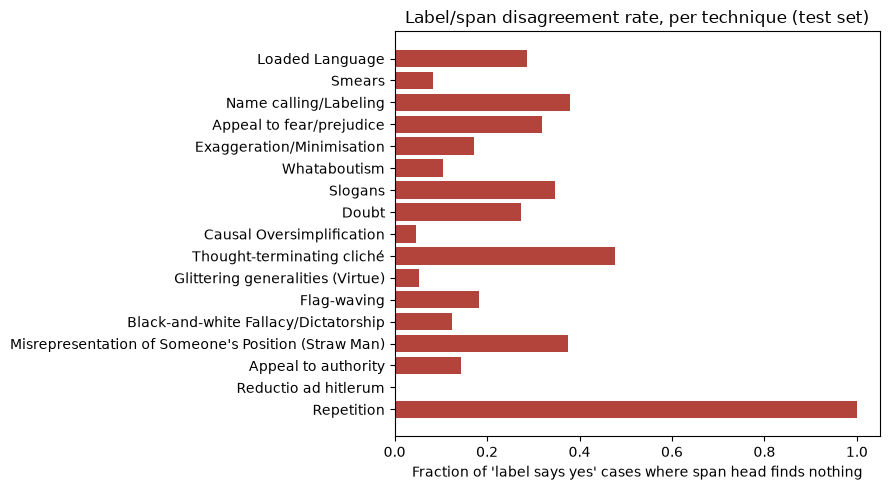

In [38]:

plot_df = agreement_df[agreement_df['label_said_yes'] > 0]
plt.figure(figsize=(9, 5))
plt.barh(plot_df['technique'], plot_df['disagreement_rate'], color='#b3443b')
plt.xlabel("Fraction of 'label says yes' cases where span head finds nothing")
plt.title("Label/span disagreement rate, per technique (test set)")
plt.gca().invert_yaxis()
plt.tight_layout(); plt.show()


The disagreement is not spread evenly. Overall the span head finds nothing 145 times out of 608 label-head "yes" calls (23.8%). The highest rates are for `Thought-terminating cliché` (47.6%), `Name calling/Labeling` (38.0%), `Slogans` (34.6%) and `Appeal to fear/prejudice` (31.9%). The lowest are for `Causal Oversimplification` (4.5%), `Smears` (8.4%) and `Whataboutism` (10.5%).

This could be because the highest rates are mostly for techniques that are short, discrete phrases, and the lowest are mostly for techniques that usually cover longer stretches of text. That would make the short ones harder for the span head to pin down. `Loaded Language` (28.7%) does not fit this cleanly, since it can colour a whole sentence and still has a middling rate. Rates for techniques with few examples, like `Thought-terminating cliché` (21 label-yes cases), are also less reliable than rates for common ones.

### C3 with the tuned span threshold

Raising the span threshold should cut the wrong spans, but it also makes it more likely that the span head finds nothing at all, which is exactly the failure C3 is about. So the tuned threshold from Part B may improve exact-span F1 and make the disagreement worse. This cell measures that trade-off on the same test set, for the default threshold and the tuned one.

In [39]:
def disagreement_at(span_threshold):
    span_token_pred = test_token_probs >= span_threshold
    span_pred_t = np.array([
        [np.any(span_token_pred[i, token_mask_bool[i], l]) for l in range(NUM_LABELS)]
        for i in range(len(test2_raw))
    ])
    label_yes_span_no_t = (test_label_pred & ~span_pred_t).sum()
    label_no_span_yes_t = (~test_label_pred & span_pred_t).sum()
    return int(label_yes_span_no_t), int(label_no_span_yes_t)

n_label_yes = int(test_label_pred.sum())
for name, thr in [('default 0.50', 0.5), (f'tuned {SPAN_THRESHOLD:.2f}', SPAN_THRESHOLD)]:
    unbacked_t, reverse_t = disagreement_at(thr)
    print(f"Span threshold {name}: label YES but span finds nothing {unbacked_t}/{n_label_yes} "
          f"({unbacked_t / n_label_yes * 100:.1f}%) | label NO but span fires {reverse_t}")

Span threshold default 0.50: label YES but span finds nothing 145/608 (23.8%) | label NO but span fires 158
Span threshold tuned 0.80: label YES but span finds nothing 484/608 (79.6%) | label NO but span fires 6


The trade-off is large. At the default span threshold of 0.50 the span head finds nothing for 145 of 608 label-head "yes" calls (23.8%), but it fires on 158 pairs where the label head said no. At the tuned threshold of 0.80 it finds nothing for 484 of 608 (79.6%), and the reverse case drops from 158 to 6. So the setting that gives the better exact-span F1 makes the failure from the brief more than three times as common. This is the precision versus coverage trade-off showing up directly where a stricter span head says less, and what it says is more often right, but the teacher is left with a label and nothing to point at for about four out of five flagged techniques. I cannot get both from this model by changing the threshold alone, which is one more reason I would not show Part B highlights to a class yet.

### What should the tool show when the heads disagree?

There are three options.

1. **Hide the label if no span backs it up:** This is simple, but it throws away a signal the label head was confident about. Since the span head is weaker at precise localisation than the label head is at detection (the exact-span result shows this), hiding on disagreement could delete many of the label head's good calls.
2. **Show the label with a "not sure" note:** This keeps the information the label head is confident about but is still honest that the system cannot point to specific words this time.
3. **Fall back to the single highest-probability token span for that technique:** even if it did not cross the span threshold, and mark it low-confidence. This gives the teacher something to discuss, but it risks pointing at the wrong words.

My recommendation is option 2. Option 1 discards a working signal, and option 3 risks teaching a Year 10 student that the wrong words are the persuasive ones, which is worse for the purpose of the product than admitting uncertainty. The disagreement rates tell me how often this will happen, but not which design is right, so this is a judgement and not a concrete, validated statement.

### C3 Conclusion

The two heads disagree often. In 23.8% of cases where the label head says a technique is present, the span head finds nothing to highlight (145 of 608). The reverse case is slightly more common (158 pairs), so fixing only the direction named in the brief would leave a similar number of cases untouched. The rate is highest for short phrase-type techniques, reaching 47.6% for `Thought-terminating cliché`, so the product needs a defined behaviour for disagreement (option 2) before the two features are shown together.

After tuning the span threshold, with the tuned threshold of 0.80 the disagreement rate rises from 23.8% to 79.6%, so the "cannot isolate" note in option 2 would appear on most flagged techniques. That makes the case for holding Part B back even stronger.

### Testing the recommendation

To check that option 2 can actually be built, here is a small function that does what I recommended. It runs one meme through the combined model, takes the techniques the label head flags, and for each one shows the words the span head found. If the span head found nothing for a flagged technique, it says so instead of leaving a label with nothing to point at. It uses the tuned label and span thresholds from earlier.

In [40]:
def explain_meme(text, label_threshold=None, span_threshold=None):
    label_threshold = BEST_THRESHOLD if label_threshold is None else label_threshold
    span_threshold = SPAN_THRESHOLD if span_threshold is None else span_threshold

    enc = tokenizer(text, truncation=True, max_length=MAX_LENGTH, padding="max_length", return_tensors="pt")
    combined_model.eval()
    with torch.inference_mode():
        meme_logits, token_logits = combined_model(enc["input_ids"].to(device), enc["attention_mask"].to(device))
    meme_probs = torch.sigmoid(meme_logits)[0].cpu().numpy()
    token_probs = torch.sigmoid(token_logits)[0].cpu().numpy()

    spans = tokens_to_spans(text, tokenizer, token_probs, span_threshold)
    results = []
    for idx in np.argsort(-meme_probs):
        if meme_probs[idx] < label_threshold:
            break
        technique = all_labels[idx]
        words = [text[s:e] for s, e, t in spans if t == technique]
        results.append({"technique": technique, "probability": round(float(meme_probs[idx]), 2), "words": words if words else None})
    return results

def show_explanation(text):
    print(f"Text: {text[:80]!r}")
    results = explain_meme(text)
    if not results:
        print("No technique detected.")
    for r in results:
        if r["words"]:
            print(f"{r['technique']} ({r['probability']}): {r['words']}")
        else:
            print(f"{r['technique']} ({r['probability']}): technique found, but cannot isolate the exact words")
    print()

for rec in test_raw[:3]:
    show_explanation(rec["text"])
show_explanation("DUTTON: TOUGH ON BORDERS, WEAK ON EVERYTHING ELSE")

Text: 'The Democrats New America\n'
  Slogans (0.53): technique found, but cannot isolate the exact words
  Smears (0.5): technique found, but cannot isolate the exact words

Text: 'WE ARE AT WAR!\n\nThere is a complex assault on our presidential election\nwith all'
  Flag-waving (0.98): ['WE', 'AT WAR']
  Slogans (0.96): technique found, but cannot isolate the exact words
  Loaded Language (0.95): ['multi', 'ted tentacles', 'terrorist organization']
  Name calling/Labeling (0.91): ['complex', 'faceted tentacles', 'terrorist organization']
  Smears (0.91): technique found, but cannot isolate the exact words
  Appeal to fear/prejudice (0.89): ['terrorist']
  Glittering generalities (Virtue) (0.85): ['ARE', 'presidential election']
  Exaggeration/Minimisation (0.7): technique found, but cannot isolate the exact words

Text: 'KILLED HIMSELF IN PRISON\n\nWON AN HONEST ELECTION\n'
  Loaded Language (0.93): technique found, but cannot isolate the exact words
  Name calling/Labeling (0.72): t

At the tuned threshold most flagged techniques come out as "cannot isolate the exact words", for example all 4 for the Dutton text and both for "The Democrats New America". Where the span head does highlight something, the quality is mixed. In the "WE ARE AT WAR!" meme some highlights look sensible ("AT WAR" for Flag-waving, "terrorist organization" for Loaded Language and Name calling), but others look wrong or broken ('ARE' for Glittering generalities, and fragments like 'multi' and 'ted tentacles'). The fragments suggest the predicted spans often start or stop in the middle of a word, which would make an exact match almost impossible even when the model is looking at the right place. A simple next step would be to extend each predicted span to whole-word boundaries and re-score. In the meantime the fallback does what I wanted where no label is shown without saying whether the words could be found.

## C1. Does It Treat All Sides the Same?

**Where the data came from:** Dimitrov et al. (2021) collected the memes from public Facebook groups over roughly three months in 2020 and 2021, with three annotators per meme and a consolidator. The paper does not describe any effort to balance political content across sides. That is not a flaw in the paper, since balance was not its goal, but it is an inherited risk here since any skew in which groups were sampled is already in the corpus before I make any modelling choice.

**Method:** Hand-written keyword lists are allowed for analysis. I use them only to tag which political figures a meme names, and not in any model decision. This is a blunt tool. It captures who is named and not whose side the meme is on, since a meme can defend a figure as easily as attack them. So it is a rough proxy and not a validated measure of political stance.

Representation across the full corpus (train+dev+test):
  mentions_neither: 678 (71.3%)
  mentions_democrat_figures: 128 (13.5%)
  mentions_republican_figures: 109 (11.5%)
  mentions_both: 36 (3.8%)


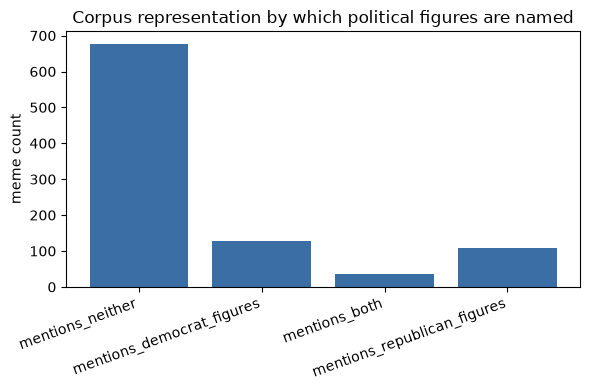

In [41]:

REPUBLICAN_KEYWORDS = ['trump', 'gop', 'republican', 'conservative', 'maga', 'pence', 'desantis']
DEMOCRAT_KEYWORDS = ['biden', 'democrat', 'liberal', 'bernie', 'sanders', 'obama', 'clinton', 'harris', 'pelosi']

def tag_side(text):
    t = text.lower()
    has_r = any(k in t for k in REPUBLICAN_KEYWORDS)
    has_d = any(k in t for k in DEMOCRAT_KEYWORDS)
    if has_r and has_d:
        return 'mentions_both'
    if has_r:
        return 'mentions_republican_figures'
    if has_d:
        return 'mentions_democrat_figures'
    return 'mentions_neither'

all_records = train_raw + dev_raw + test_raw
side_counts = Counter(tag_side(d['text']) for d in all_records)
print("Representation across the full corpus (train+dev+test):")
for side, count in side_counts.most_common():
    print(f"  {side}: {count} ({count/len(all_records)*100:.1f}%)")

plt.figure(figsize=(6, 4))
plt.bar(side_counts.keys(), side_counts.values(), color='#3b6ea5')
plt.xticks(rotation=20, ha='right'); plt.ylabel('meme count')
plt.title('Corpus representation by which political figures are named')
plt.tight_layout(); plt.show()


### Does the ground truth already skew by side?

Before asking whether the model is biased, I check whether the data is. If attack-style techniques are labelled more often against one side in the source data, even a fair model trained on it would copy that skew.

In [50]:

ATTACK_TECHNIQUES = ['Name calling/Labeling', 'Smears', 'Loaded Language', 'Appeal to fear/prejudice', 'Reductio ad hitlerum']

def attack_rate(records, side):
    subset = [d for d in records if tag_side(d['text']) == side]
    if not subset:
        return float('nan'), 0
    rate = sum(1 for d in subset if any(l in ATTACK_TECHNIQUES for l in d['labels'])) / len(subset)
    return rate, len(subset)

for side in ['mentions_republican_figures', 'mentions_democrat_figures']:
    rate, n = attack_rate(train_raw, side)
    print(f"Training set {side}: {rate*100:.1f}% of memes carry at least one attack-style label (n={n})")


Training set mentions_republican_figures: 78.3% of memes carry at least one attack-style label (n=69)
Training set mentions_democrat_figures: 76.3% of memes carry at least one attack-style label (n=93)


### Does the model do equally well on both sides?

The question that matters in a classroom is whether the model catches an attack-style technique equally often whichever side is attacked. That is recall, measured separately for each side on the test set.

In [43]:

test_sides = np.array([tag_side(d['text']) for d in test_raw])
attack_idx = [LABEL_TO_IDX[t] for t in ATTACK_TECHNIQUES]

print(f"{'Side':<30}{'n':<6}{'Attack-label recall':<22}{'Attack-label precision'}")
for side in ['mentions_republican_figures', 'mentions_democrat_figures']:
    mask = test_sides == side
    n = mask.sum()
    if n == 0:
        print(f"{side:<30}{0:<6}(no test examples)")
        continue
    true_subset = test_true[mask][:, attack_idx]
    pred_subset = test_preds[mask][:, attack_idx]
    precision, recall, _, _ = precision_recall_fscore_support(
        true_subset, pred_subset, average='micro', zero_division=0)
    print(f"{side:<30}{n:<6}{recall:<22.3f}{precision:.3f}")


Side                          n     Attack-label recall   Attack-label precision
mentions_republican_figures   27    0.875                 0.406
mentions_democrat_figures     28    0.767                 0.434


In the training data the attack-technique rates are close: 78.3% of memes naming Republican figures (n=69) and 76.3% of those naming Democrat figures (n=93). So the source labels are not strongly skewed. On the test set, recall is 0.875 for Republican-named memes (n=27) and 0.767 for Democrat-named memes (n=28), a gap of about 11 points. Precision goes the other way, 0.406 against 0.434. Higher recall with lower precision on the Republican side fits a model that flags those memes as attacks a little more readily, and not one that is simply better at them.

The groups are small, with 27 and 28 memes, so a few examples either way could move these numbers a lot, and I have no confidence interval. The training skew is only about 2 points, so the recall gap is bigger than the data would predict, but I cannot rule out chance.

### C1 Conclusion

I found a recall gap of about 11 points between the two groups that is larger than the 2-point training-data skew. With 27 to 28 memes per group and a keyword proxy for side, the evidence is a flag to watch and not proof of bias. Before classroom use I would check it on more data.

## C2. Defend the System You Built

**Comparison model: facebook/bart-large-mnli**, through the zero-shot-classification pipeline. I chose it over a large generative LLM for two reasons:

1. **It runs entirely locally:** No hosted API call is needed and no meme text leaves the device, which matches the product's own privacy rule even though C2 itself allows an external call for this evaluation.
2. **Contamination is much less of a worry:** It is fine-tuned on MNLI (crowd-sourced sentence-pair judgements) and not trained on web data at the scale of a generative LLM, so it is very unlikely to have memorised these fairly obscure memes. A large web-scale LLM would raise that question and be hard to answer.

**How multi-label zero-shot works here:** The pipeline checks each of the 20 technique names against the meme text as its own entailment question ("this meme uses the persuasion technique: X"), with multi_label=True so the checks are independent and do not have to add up to one. That matches the multi-label structure of the task.

In [44]:

from transformers import pipeline

zero_shot = pipeline("zero-shot-classification", model="facebook/bart-large-mnli",
                      device=0 if torch.cuda.is_available() else -1)

HYPOTHESIS_TEMPLATE = "This meme uses the persuasion technique: {}."
ZS_THRESHOLD = 0.5
N_SAMPLE = 40

random.seed(SEED)
sample_idx = random.sample(range(len(test_raw)), min(N_SAMPLE, len(test_raw)))
sample_records = [test_raw[i] for i in sample_idx]

print(f"Model: facebook/bart-large-mnli")
print(f"Hypothesis template: \"{HYPOTHESIS_TEMPLATE}\"")
print(f"multi_label=True, threshold={ZS_THRESHOLD}")
print(f"Sample size: {len(sample_records)} / {len(test_raw)} test memes, seed={SEED}")
print(f"Run date: see notebook execution timestamp")


Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

Model: facebook/bart-large-mnli
Hypothesis template: "This meme uses the persuasion technique: {}."
multi_label=True, threshold=0.5
Sample size: 40 / 200 test memes, seed=42
Run date: see notebook execution timestamp


In [45]:

zs_preds, zs_true = [], []
for rec in sample_records:
    result = zero_shot(rec["text"], candidate_labels=all_labels,
                        hypothesis_template=HYPOTHESIS_TEMPLATE, multi_label=True)
    pred_vec = np.zeros(NUM_LABELS)
    for label, score in zip(result["labels"], result["scores"]):
        if score >= ZS_THRESHOLD:
            pred_vec[LABEL_TO_IDX[label]] = 1.0
    zs_preds.append(pred_vec)

    true_vec = np.zeros(NUM_LABELS)
    for label in rec["labels"]:
        true_vec[LABEL_TO_IDX[label]] = 1.0
    zs_true.append(true_vec)

zs_preds = np.array(zs_preds)
zs_true = np.array(zs_true)
print(f"Zero-shot predictions collected for {len(sample_records)} memes.")


Zero-shot predictions collected for 40 memes.


### Same metric, same sample with both systems

                   System  Micro-F1  Macro-F1
Our fine-tuned DistilBERT  0.351220  0.157402
Zero-shot BART-large-MNLI  0.149031  0.122189


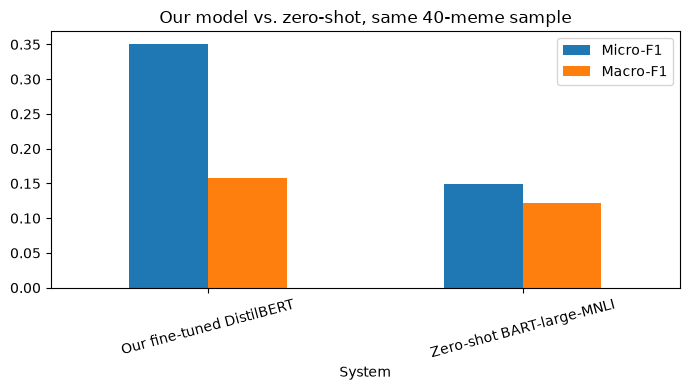

In [46]:

our_preds_sample = test_preds[sample_idx]
our_true_sample = test_true[sample_idx]
assert np.array_equal(our_true_sample, zs_true), "Gold labels must match between the two systems on the same sample"

comparison = pd.DataFrame({
    'System': ['Our fine-tuned DistilBERT', 'Zero-shot BART-large-MNLI'],
    'Micro-F1': [
        f1_score(our_true_sample, our_preds_sample, average='micro', zero_division=0),
        f1_score(zs_true, zs_preds, average='micro', zero_division=0),
    ],
    'Macro-F1': [
        f1_score(our_true_sample, our_preds_sample, average='macro', zero_division=0),
        f1_score(zs_true, zs_preds, average='macro', zero_division=0),
    ],
})
print(comparison.to_string(index=False))

comparison.set_index('System')[['Micro-F1', 'Macro-F1']].plot.bar(figsize=(7, 4), rot=15)
plt.title(f'Our model vs. zero-shot, same {len(sample_records)}-meme sample')
plt.tight_layout(); plt.show()


On the same 40 test memes (seed 42), my fine-tuned DistilBERT scored micro-F1 0.351 and macro-F1 0.157, against 0.149 and 0.122 for zero-shot BART. My model is more than twice as good on micro-F1, but the macro-F1 gap is much smaller, so the advantage is mostly on the common techniques. A 40-meme sample is noisy, so these numbers show the size and direction of the gap and should not be quoted as precise estimates.

### C2 Conclusion

The model I built clearly beats the off-the-shelf zero-shot model on micro-F1 (0.351 against 0.149) and is slightly ahead on macro-F1 (0.157 against 0.122), on a small sample. That justifies building it. The case is stronger because it is small (about 67M parameters against a much bigger BART), fast, and runs locally for privacy, but the macro-F1 result says it is still weak on rare techniques.


## Bootstrap Confidence Intervals

All my results come from one trained model and a small test set, and C1 and C2 in particular rest on a few dozen memes. A single F1 or recall value does not show how much it could move with a different sample, so I put a 95% confidence interval on the main comparisons. I use the bootstrap, resample the memes with replacement 1000 times, recompute the number each time, and take the middle 95% of the results. This only measures sampling noise in the test memes. It does not capture the variation from retraining with a different seed.

In [51]:
def bootstrap_ci(metric_fn, n_items, n_boot=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    scores = np.array([metric_fn(rng.integers(0, n_items, n_items)) for _ in range(n_boot)], dtype=float)
    return np.nanpercentile(scores, [2.5, 97.5])

# 1. Part A test scores
for name, avg in [('micro', 'micro'), ('macro', 'macro')]:
    fn = lambda idx, avg=avg: f1_score(test_true[idx], test_preds[idx], average=avg, zero_division=0)
    lo, hi = bootstrap_ci(fn, len(test_true))
    print(f"Part A test {name}-F1: {fn(np.arange(len(test_true))):.3f}  (95% CI {lo:.3f} to {hi:.3f})")

# 2. C1: recall gap between the two political groups (resampling inside each group)
def attack_recall(idx):
    t = test_true[idx][:, attack_idx]
    p = test_preds[idx][:, attack_idx]
    return (t * p).sum() / t.sum() if t.sum() > 0 else np.nan

rep_idx = np.where(test_sides == 'mentions_republican_figures')[0]
dem_idx = np.where(test_sides == 'mentions_democrat_figures')[0]
rng = np.random.default_rng(SEED)
gaps = np.array([attack_recall(rng.choice(rep_idx, len(rep_idx))) - attack_recall(rng.choice(dem_idx, len(dem_idx)))
                 for _ in range(1000)])
lo, hi = np.nanpercentile(gaps, [2.5, 97.5])
print(f"C1 recall gap (Republican minus Democrat): {attack_recall(rep_idx) - attack_recall(dem_idx):.3f}  (95% CI {lo:.3f} to {hi:.3f})")
print(f"share of resamples where the gap is positive: {np.nanmean(gaps > 0):.2f}")

# 3. C2: micro-F1 difference between my model and zero-shot on the same 40 memes
c2_fn = lambda idx: (f1_score(our_true_sample[idx], our_preds_sample[idx], average='micro', zero_division=0)
                     - f1_score(zs_true[idx], zs_preds[idx], average='micro', zero_division=0))
lo, hi = bootstrap_ci(c2_fn, len(our_true_sample))
print(f"C2 micro-F1 difference (mine minus zero-shot): {c2_fn(np.arange(len(our_true_sample))):.3f}  (95% CI {lo:.3f} to {hi:.3f})")

Part A test micro-F1: 0.394  (95% CI 0.363 to 0.428)
Part A test macro-F1: 0.218  (95% CI 0.186 to 0.247)
C1 recall gap (Republican minus Democrat): 0.108  (95% CI -0.114 to 0.319)
share of resamples where the gap is positive: 0.83
C2 micro-F1 difference (mine minus zero-shot): 0.202  (95% CI 0.139 to 0.267)


The Part A test scores are fairly well pinned down by the 200 test memes: micro-F1 0.394 (0.363 to 0.428) and macro-F1 0.218 (0.186 to 0.247). The micro-F1 interval includes the 0.374 of the trivial baseline, while the macro-F1 interval is far above the baseline's 0.033. For C1, the recall gap of 0.108 has an interval from -0.114 to 0.319, and the gap is positive in 83% of resamples. So I cannot rule out that there is no gap at all. The data are consistent with a gap in the direction I measured, but they do not show the model is biased. For C2, the micro-F1 advantage over zero-shot is 0.202 (0.139 to 0.267) and the interval stays clear of zero, so on this 40-meme sample the advantage is not just noise. These intervals only cover the choice of test memes. They do not include the variation I would get from retraining with a different seed, which was not tested yet.

## C4. Will It Work Here?

There is no labelled Australian classroom data, so the evidence cannot be a normal held-out test set and has to be designed. I ran two experiments with the limited data.

### Experiment 1: Entity substitution

I took real training memes with known labels and made Australian versions by swapping only the named entities and country-specific words, keeping the sentence structure, and so the technique, the same. If predictions shift a lot after a swap that should not matter, the model is keying on specific US figures instead of the language pattern of the technique.

In [48]:

ENTITY_SUBSTITUTIONS = {
    'biden': 'albanese', 'trump': 'dutton', 'america': 'australia',
    'american': 'australian', 'congressman': 'mp', 'republican': 'liberal',
    'democrat': 'labor', 'washington': 'canberra',
}

def substitute_entities(text):
    result = text
    for us_term, au_term in ENTITY_SUBSTITUTIONS.items():
        result = result.replace(us_term, au_term)
        result = result.replace(us_term.capitalize(), au_term.capitalize())
        result = result.replace(us_term.upper(), au_term.upper())
    return result

candidates = [d for d in train_raw if any(k in d['text'].lower() for k in ENTITY_SUBSTITUTIONS)][:8]
print(f"Found {len(candidates)} training memes containing a substitutable entity.")

model.eval()
shift_results = []
for rec in candidates:
    au_text = substitute_entities(rec['text'])
    if au_text == rec['text']:
        continue
    enc_orig = tokenizer(rec['text'], padding='max_length', truncation=True, max_length=MAX_LENGTH, return_tensors='pt')
    enc_au = tokenizer(au_text, padding='max_length', truncation=True, max_length=MAX_LENGTH, return_tensors='pt')
    with torch.inference_mode():
        prob_orig = torch.sigmoid(model(**{k: v.to(device) for k, v in enc_orig.items()}).logits).cpu().numpy()[0]
        prob_au = torch.sigmoid(model(**{k: v.to(device) for k, v in enc_au.items()}).logits).cpu().numpy()[0]
    shift = np.abs(prob_orig - prob_au).mean()
    shift_results.append({'original': rec['text'][:50], 'au_variant': au_text[:50], 'mean_abs_prob_shift': shift})

shift_df = pd.DataFrame(shift_results).sort_values('mean_abs_prob_shift', ascending=False)
print(shift_df.to_string(index=False))
print(f"\nMean shift across all pairs: {shift_df['mean_abs_prob_shift'].mean():.4f}")
print("(0 = entity swap had no effect on predictions; larger = model is sensitive to the specific named entity)")


Found 8 training memes containing a substitutable entity.
                                               original                                              au_variant  mean_abs_prob_shift
     WHEN YOUR TAXES ARE FINALLY USED TO KILL TERRORIST      WHEN YOUR TAXES ARE FINALLY USED TO KILL TERRORIST             0.128951
   TRUMP CURES CORONAVIRUS!\n\nCURING CORONA VIRUS IS R    DUTTON CURES CORONAVIRUS!\n\nCURING CORONA VIRUS IS              0.114139
  SCARE TATICS BY THE LEFT.\n\nClose businesses\nClose    SCARE TATICS BY THE LEFT.\n\nClose businesses\nClose              0.051615
PATHETIC\n\nThe Cowardly Asshole\nWeak Failure!!!\n\nIm PATHETIC\n\nThe Cowardly Asshole\nWeak Failure!!!\n\nIm             0.038983
    Adolf Hitler\n• Believed state power would fix Germ     Adolf Hitler\n• Believed state power would fix Germ             0.031006
     CALM DOWN LITTLE TRUMP HATER\nI FOUND YOUR BINKY\n     CALM DOWN LITTLE DUTTON HATER\nI FOUND YOUR BINKY\n             0.008742
   SO BERNI

### Experiment 2: Original Australian-context examples

I wrote five short texts for this check using Australian 2026 figures and topics (Albanese, Dutton, cost of living, immigration, the RBA), each built to use one specific technique.

In [49]:

au_examples = [
    {"text": "ALBANESE SAYS HE'LL FIX THE COST OF LIVING\n\nJUST LIKE HE FIXED EVERYTHING ELSE. OH WAIT.",
     "intended_technique": "Loaded Language"},
    {"text": "DUTTON: TOUGH ON BORDERS, WEAK ON EVERYTHING ELSE",
     "intended_technique": "Name calling/Labeling"},
    {"text": "IF WE DON'T STOP IMMIGRATION NOW, THERE WON'T BE A COUNTRY LEFT FOR OUR KIDS",
     "intended_technique": "Appeal to fear/prejudice"},
    {"text": "AUSTRALIA: LOVE IT OR LEAVE IT",
     "intended_technique": "Slogans"},
    {"text": "THE WHOLE COST OF LIVING CRISIS IS JUST THE RBA'S FAULT, NOTHING ELSE MATTERS",
     "intended_technique": "Causal Oversimplification"},
]

model.eval()
for ex in au_examples:
    enc = tokenizer(ex["text"], padding='max_length', truncation=True, max_length=MAX_LENGTH, return_tensors='pt')
    with torch.inference_mode():
        probs = torch.sigmoid(model(**{k: v.to(device) for k, v in enc.items()}).logits).cpu().numpy()[0]
    predicted = [all_labels[i] for i in range(NUM_LABELS) if probs[i] >= BEST_THRESHOLD]
    intended_prob = probs[LABEL_TO_IDX[ex["intended_technique"]]]
    print(f"Text: {ex['text'][:60]!r}")
    print(f"  Intended: {ex['intended_technique']} (model's probability for it: {intended_prob:.3f})")
    print(f"  Model predicted: {predicted if predicted else '(nothing above threshold)'}")
    print()


Text: "ALBANESE SAYS HE'LL FIX THE COST OF LIVING\n\nJUST LIKE HE FIX"
  Intended: Loaded Language (model's probability for it: 0.125)
  Model predicted: ['Doubt', 'Exaggeration/Minimisation']

Text: 'DUTTON: TOUGH ON BORDERS, WEAK ON EVERYTHING ELSE'
  Intended: Name calling/Labeling (model's probability for it: 0.496)
  Model predicted: ['Loaded Language', 'Name calling/Labeling', 'Slogans', 'Smears']

Text: "IF WE DON'T STOP IMMIGRATION NOW, THERE WON'T BE A COUNTRY L"
  Intended: Appeal to fear/prejudice (model's probability for it: 0.766)
  Model predicted: ['Appeal to fear/prejudice', 'Causal Oversimplification', 'Doubt', 'Exaggeration/Minimisation', 'Loaded Language']

Text: 'AUSTRALIA: LOVE IT OR LEAVE IT'
  Intended: Slogans (model's probability for it: 0.107)
  Model predicted: (nothing above threshold)

Text: "THE WHOLE COST OF LIVING CRISIS IS JUST THE RBA'S FAULT, NOT"
  Intended: Causal Oversimplification (model's probability for it: 0.011)
  Model predicted: ['Exaggerati

### What goes wrong in the gap, and why

There are three separate gaps and not one:
- **Entity gap**: the model might have learned that mentions of Biden or Trump go with certain techniques as a shortcut. That would fail silently on Australian names it has never seen.
- **Structural or platform gap:** the paper notes these memes are "full of uppercase characters" and come from Facebook groups in 2020 and 2021. A 2026 Australian teenager's feed is more likely TikTok or Instagram formatting with different slang and templates, which the model has never seen.
- **Topical gap:** the training content centres on 2020 to 2021 US events (COVID, that election). An Australian classroom in 2026 is more likely to show cost of living, immigration or local politicians, which are absent from training apart from whatever general technique language carries over.

### The non-technical side

A wrong label is not a harmless mistake. Imagine the tool labels a meme as Smears or Name calling/Labeling in front of a class, and the meme touches on a student’s own family’s politics. The teacher then has to either defend a tool they did not build or contradict it in front of everyone, and either way the student ends up in the spotlight. For this reason, the tool should be presented as a discussion starter that the teacher controls, not as something that has a final say. That is a product and training decision as much as a modelling one, and it does not need the modelling gap to be closed first.

### C4 Conclusion

**Experiment 1:** the mean absolute probability shift across all pairs was 0.0482, and 5 of the 8 memes shifted by less than 0.04. Only two shifted by more than 0.1: 0.129 (the "taxes used to kill terrorist" meme) and 0.114 ("Trump cures coronavirus" changed to Dutton). So the model is not strongly dependent on the named entity, at least for these 8 memes.

**Experiment 2:** it got 2 of 5 right. `Name calling/Labeling` for the Dutton text came out at 0.496 and `Appeal to fear/prejudice` for the immigration text at 0.766. It missed the other three: the Albanese text (0.125, predicted Doubt and Exaggeration/Minimisation instead), "Love it or leave it" (0.107, nothing predicted), and the RBA text (0.011). The two hits also came with several extra labels, so part of the success may just be the model over-predicting. The RBA miss looks like a vocabulary problem and not an entity problem, since "RBA" has no US equivalent in training, and the attention plot above points the same way.

Overall the model keeps some robustness to name changes but misses on vocabulary and topics it has not seen. With 8 swaps and 5 examples that were written by myself, this is an early warning and not a measured failure rate, and it is not a substitute for labelled Australian data.

### Part C: Summary

- **C1:** recall was 0.875 for Republican-named memes and 0.767 for Democrat-named ones, a gap of 0.108 that is larger than the 2-point training skew. The bootstrap interval (-0.114 to 0.319) includes zero, so this is a flag and not proof of bias.
- **C2:** my fine-tuned model scored micro-F1 0.351 against 0.149 for local zero-shot BART on 40 memes. The difference of 0.202 has an interval of 0.139 to 0.267, so it is not just noise, but the macro-F1 gap is smaller (0.157 against 0.122).
- **C3:** the span head found nothing for 23.8% of label-head "yes" calls at the default threshold, and for 79.6% at the tuned threshold that gives the best exact-span F1. I recommend showing the label with a "not sure" note, and holding Part B back.
- **C4:** entity swaps moved predictions only 0.0482 on average, but the model got 2 of 5 of my Australian examples right and missed on vocabulary like "RBA". This is an early warning and not a fully validated measure.

## Ultimate Judgement

Taking Part A, B, and the four Part C investigations together:

- Part A is realistic for a supervised pilot as a label-only feature for the common techniques, with a clear warning to teachers that rare techniques are unreliable. Its micro-F1 is close to a trivial baseline, so the case rests on the per-technique results and macro-F1.
- Part B is not realistic for classroom use yet. Exact-span F1 is 0.061 on test, against 0.288 for the lenient token-level measure. The words shown to a student would often be wrong, too broad, or not quite aligned to the right words, which works against the teaching goal.
- C1 is an amber flag. The recall gap is 0.108, but the bootstrap interval (-0.114 to 0.319) includes zero and each group has under 30 memes. It should be re-checked on more data before anyone claims the tool is fair across political content.
- In C2, the model beats a local zero-shot model on micro-F1 (0.351 vs 0.149 on 40 memes), but the macro-F1 gap is small (0.157 vs 0.122). This supports building the model, but it does not show that the model handles rare techniques.
- For C3, at the default span threshold, the span head finds nothing to highlight for 23.8% of the techniques the label head detects. At the tuned threshold this rises to 79.6%. Even Part A labels shown next to Part B highlights would often have nothing to point at, so a defined fallback is a prerequisite for combining the two features.
- C4 gives early evidence that the model copes with swapped names (average probability shift of 0.048), but it missed Australian vocabulary and local slogans. This rests on 8 name swaps and 5 self-written examples, so it is a warning and not a measured failure rate. Without local data, similar misses are likely in an actual Australian classroom.


## Deployment Ready

It is not ready for unsupervised, full-feature use. It is realistic as a supervised pilot of the label-only feature with teacher supervision, clear warnings about rare techniques and political-fairness uncertainty, and 
Part B held back until its span accuracy and head-agreement problems are fixed.

What I would do in a trial, based on the evidence above:
- **Show labels as ‘possible techniques’ and mark weak techniques as low reliability:** On test, only Loaded Language (F1 0.745), Name calling (0.492), Smears (0.431) and Doubt (0.394) are above 0.39, and the rest are 0.375 or lower.
- **Treat errors by severity:** where a wrong Smears or Name calling label on a student's own political content is worse than a missed technique. On test the precision of those two is low (0.295 and 0.346) while recall is high (0.800 and 0.849), so roughly two in three flags are wrong. For those techniques I would raise the threshold or show them with extra caution.
- **Accountability and monitoring:** log each prediction with the teacher's accept or reject choice (stored on the device, technique labels only and no meme text, to respect the privacy rule), review the accept rate each term, and retrain when it drops or when Australian examples have been collected with consent. Someone must own this. I would suggest the curriculum committee that commissioned the tool, with the teacher as the first line of review.
- **Operational checks:** latency on a CPU was 146 ms per meme in one run and 169 ms in the latest saved run. These need checking on the real hardware before a pilot.
- **Evidence from outside the SemEval data is thin:** The only checks outside the provided splits are the eight name swaps and the five Australian examples I wrote (C4). A pilot should start with a small set of real Australian memes labelled by teachers, used as a beginning test before wider use.


## Known Gaps

- Explainability was run on only a few hand-picked examples, and the results suggest some reliance on emotive keywords. Attention is also not a faithful explanation of what the model does. Future work would be to run leave-one-out over a few hundred memes and count which words drive each technique, to test the keyword hypothesis at scale.
- The Part B combined loss weights the meme-level and token-level terms equally and I did not tune it. Future work would be to try a few weights on dev and compare.
- Predicted spans often start or stop mid-word, so exact matches are rare even when the model looks at the right place (for example "multi" and "ted tentacles"). Future work would be to extend predicted spans to whole-word boundaries and re-score on dev.
- Rare techniques have too few examples (several have fewer than 10 test examples and 0 to 3 dev examples), and two taxonomy techniques (Transfer and Appeal to (Strong) Emotions) have none. Future work would be to collect or label more examples of the rare techniques and handle the two unseen ones explicitly in the product.
- There is no real Australian data. Future work should have teachers label a small set of Australian memes and use it as a test set.
- The span head trades precision against coverage (C3), and the threshold alone cannot fix that. Future work would be to include more span training data or a different span objective.
